# **Intelligent Microscopic Blood Cell Classification for Leukemia Detection Using Deep Learning**

Blood Cell Classification for Leukemia Detection uses deep learning to classify blood cell images into different cell types. The project evaluates CNN-ML, CBAM-DenseNet19, and Vision Transformer models using accuracy, precision, recall, F1-score, and log loss. It compares their classification performance to identify the most effective model. The aim is to support leukemia screening through automated blood cell image analysis, complementing rather than replacing clinical diagnosis.

## **Import Required Libraries**

In [ ]:
# Import standard libraries and configure reproducibility.
import os
import random
import warnings
from pathlib import Path
import joblib
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image,ImageOps, ImageFile, UnidentifiedImageError
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras import models

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, log_loss,confusion_matrix, classification_report, precision_recall_curve,average_precision_score
from sklearn.preprocessing import label_binarize

warnings.filterwarnings("ignore", category=UserWarning)
ImageFile.LOAD_TRUNCATED_IMAGES = False

In [ ]:
# Set random seeds to improve reproducibility across experiments.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Configure image preprocessing and model training.
IMAGE_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 10
AUTOTUNE = tf.data.AUTOTUNE

# Display the installed TensorFlow version and available hardware.
print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## **Dataset Loading and Understanding**

In [ ]:
# Dataset path
DATASET_PATH = Path("/kaggle/input/datasets/sumithsingh/blood-cell-images-for-cancer-detection")

# Verify that the configured dataset directory exists
if not DATASET_PATH.exists():
    raise FileNotFoundError(f"Dataset directory not found: {DATASET_PATH}")

print("Dataset directory:", DATASET_PATH)

Dataset directory: /kaggle/input/datasets/sumithsingh/blood-cell-images-for-cancer-detection


In [ ]:
# Define the image extensions accepted by the dataset scanner.
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

# Identify immediate subdirectories that contain images.
class_dirs = sorted([path for path in DATASET_PATH.iterdir() if path.is_dir()])

# Stop if the directory does not contain class folders.
if not class_dirs:
    raise ValueError("No class folders were found. Check DATASET_PATH.")

# Collect image paths and their corresponding class labels.
image_records = []

for class_dir in class_dirs:
    image_files = [path for path in class_dir.rglob("*") if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS]
    for image_path in image_files:
        image_records.append({"image_path": str(image_path), "label": class_dir.name})

In [ ]:
# Create a metadata DataFrame for the discovered images.
metadata_df = pd.DataFrame(image_records)

# Validate the metadata and display the discovered classes.
if metadata_df.empty:
    raise ValueError("No supported image files were found in the class folders.")

CLASS_NAMES = sorted(metadata_df["label"].unique().tolist())
CLASS_TO_IDX = {class_name: index for index, class_name in enumerate(CLASS_NAMES)}
IDX_TO_CLASS = {index: class_name for class_name, index in CLASS_TO_IDX.items()}

metadata_df["label_idx"] = metadata_df["label"].map(CLASS_TO_IDX)

print("Number of classes:", len(CLASS_NAMES))
print("Class names:", CLASS_NAMES)
print("Total discovered images:", len(metadata_df))
display(metadata_df.head())

Number of classes: 5
Class names: ['basophil', 'erythroblast', 'monocyte', 'myeloblast', 'seg_neutrophil']
Total discovered images: 5000


,image_path,label,label_idx
0,/kaggle/input/datasets/sumithsingh/blood-cell-...,basophil,0
1,/kaggle/input/datasets/sumithsingh/blood-cell-...,basophil,0
2,/kaggle/input/datasets/sumithsingh/blood-cell-...,basophil,0
3,/kaggle/input/datasets/sumithsingh/blood-cell-...,basophil,0
4,/kaggle/input/datasets/sumithsingh/blood-cell-...,basophil,0


In [ ]:
# Validate one image by checking whether it can be opened and its basic metadata can be read.
def validate_single_image(record):
    # Retrieve the image file path and its corresponding class label.
    image_path = record.image_path
    label = record.label

    # Convert the class label into its numerical index.
    label_idx = CLASS_TO_IDX[label]

    try:
        # Open the image file and automatically close it after validation.
        with Image.open(image_path) as img:
            # Correct the image orientation using its EXIF metadata.
            # Accessing the image dimensions helps identify files that cannot be read properly.
            img_transposed = ImageOps.exif_transpose(img)

            # Extract the image width and height after correcting its orientation.
            width, height = img_transposed.size

            # Retrieve the image format reported by Pillow.
            image_format = img.format

        # Return the image metadata and validation status.
        return {
            "image_path": image_path,
            "label": label,
            "label_idx": label_idx,
            "width": width,
            "height": height,
            "image_format": image_format,
            "is_valid": width > 0 and height > 0
        }

    # Handle files that are corrupted, unreadable, truncated, or in an unsupported format.
    except (OSError, ValueError, UnidentifiedImageError) as error:
        # Return the file details and mark the image as invalid.
        return {
            "image_path": image_path,
            "label": label,
            "label_idx": label_idx,
            "width": None,
            "height": None,
            "image_format": None,
            "is_valid": False
        }

In [ ]:
# Convert the metadata DataFrame rows into namedtuples for parallel processing.
records = list(metadata_df.itertuples(index=False))

# Set the number of worker threads based on available CPU resources, with a maximum of 32.
max_workers = min(32, (os.cpu_count() or 1) * 4)

# Validate multiple image files concurrently to reduce I/O processing time.
with ThreadPoolExecutor(max_workers=max_workers) as executor:
    # Process each image record and display a progress bar during validation.
    validation_records = list(tqdm(executor.map(validate_single_image, records), total=len(records), desc="Validating images"))

# Store all image validation results in a DataFrame.
validation_df = pd.DataFrame(validation_records)

# Keep valid images in a separate DataFrame and reset their row indices.
valid_images_df = validation_df[validation_df["is_valid"]].copy().reset_index(drop=True)

# Keep invalid or unreadable images separately for further investigation.
invalid_images_df = validation_df[~validation_df["is_valid"]].copy().reset_index(drop=True)

# Display the total number of discovered, valid, and invalid images.
print("Discovered images:", len(metadata_df))
print("Valid images:", len(valid_images_df))
print("Invalid or unreadable images:", len(invalid_images_df))

# Count metadata paths that do not point to existing files.
print("Missing file paths:", int((~metadata_df["image_path"].map(lambda path: Path(path).exists())).sum()))

# Display the first 20 invalid image paths and their labels if any invalid files were found.
if not invalid_images_df.empty:
    display(invalid_images_df[["image_path", "label"]].head(20))

Validating images:   0%|          | 0/5000 [00:00<?, ?it/s]

Discovered images: 5000
Valid images: 5000
Invalid or unreadable images: 0
Missing file paths: 0


In [ ]:
# Calculate class counts and proportions from validated images.
class_counts = valid_images_df["label"].value_counts().reindex(CLASS_NAMES, fill_value=0)
class_percentages = (class_counts / len(valid_images_df) * 100).round(2)

class_distribution_df = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Image Count": class_counts.values,
    "Percentage (%)": class_percentages.values
})

# Summarize image dimensions and file formats.
image_statistics = {
    "Total discovered images": len(metadata_df),
    "Valid images": len(valid_images_df),
    "Invalid or unreadable images": len(invalid_images_df),
    "Number of classes": len(CLASS_NAMES),
    "Minimum width": valid_images_df["width"].min(),
    "Maximum width": valid_images_df["width"].max(),
    "Average width": round(valid_images_df["width"].mean(), 2),
    "Minimum height": valid_images_df["height"].min(),
    "Maximum height": valid_images_df["height"].max(),
    "Average height": round(valid_images_df["height"].mean(), 2)
}

In [ ]:
print("Dataset Statistics")
for statistic, value in image_statistics.items():
    print(f"{statistic}: {value}")

Dataset Statistics
Total discovered images: 5000
Valid images: 5000
Invalid or unreadable images: 0
Number of classes: 5
Minimum width: 360
Maximum width: 400
Average width: 376.1
Minimum height: 360
Maximum height: 400
Average height: 377.88


In [ ]:
# Class Distributions
print("Class Distribution")
display(class_distribution_df)

Class Distribution


,Class,Image Count,Percentage (%)
0,basophil,1000,20.0
1,erythroblast,1000,20.0
2,monocyte,1000,20.0
3,myeloblast,1000,20.0
4,seg_neutrophil,1000,20.0


In [ ]:
# Image Format Counts
print("Image Format Counts")
display(valid_images_df["image_format"].value_counts().rename_axis("Format").reset_index(name="Count"))

Image Format Counts


,Format,Count
0,JPEG,5000


## **Exploratory Data Analysis**



In [ ]:
# Define the project color palette.
COLORS = ["#af1717", "#d64133", "#fe6550", "#ff876f", "#ffab8f"]

# Configure plot typography.
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "axes.titlesize": 16,
    "axes.labelsize": 13,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "text.color": "grey",
    "axes.labelcolor": "grey",
    "xtick.color": "grey",
    "ytick.color": "grey",
    "axes.titleweight": "bold",
    "axes.labelweight": "bold",
    "font.weight": "bold"
})
sns.set_style("whitegrid")

In [ ]:
# Select a reproducible sample for computationally intensive EDA operations.
EDA_SAMPLE_SIZE = min(1000, len(valid_images_df))
eda_sample_df = valid_images_df.sample(n=EDA_SAMPLE_SIZE, random_state=SEED).reset_index(drop=True)

# Cache loaded, resized RGB images so later EDA plots can reuse them.
eda_images = []
eda_labels = []

for record in tqdm(eda_sample_df.itertuples(index=False), total=len(eda_sample_df), desc="Loading EDA sample"):
    try:
        with Image.open(record.image_path) as image:
            image = ImageOps.exif_transpose(image).convert("RGB")
            image = image.resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.LANCZOS)
            eda_images.append(np.asarray(image, dtype=np.uint8))
            eda_labels.append(record.label)
    except (OSError, ValueError, UnidentifiedImageError):
        continue

# Convert the loaded images and labels into NumPy arrays.
eda_images = np.asarray(eda_images, dtype=np.uint8)
eda_labels = np.asarray(eda_labels)

if len(eda_images) == 0:
    raise ValueError("No images could be loaded for EDA. Check the dataset paths.")

print("EDA images loaded:", len(eda_images))
print("EDA image array shape:", eda_images.shape)
print("EDA classes represented:", sorted(np.unique(eda_labels).tolist()))

Loading EDA sample:   0%|          | 0/1000 [00:00<?, ?it/s]

EDA images loaded: 1000
EDA image array shape: (1000, 224, 224, 3)
EDA classes represented: ['basophil', 'erythroblast', 'monocyte', 'myeloblast', 'seg_neutrophil']


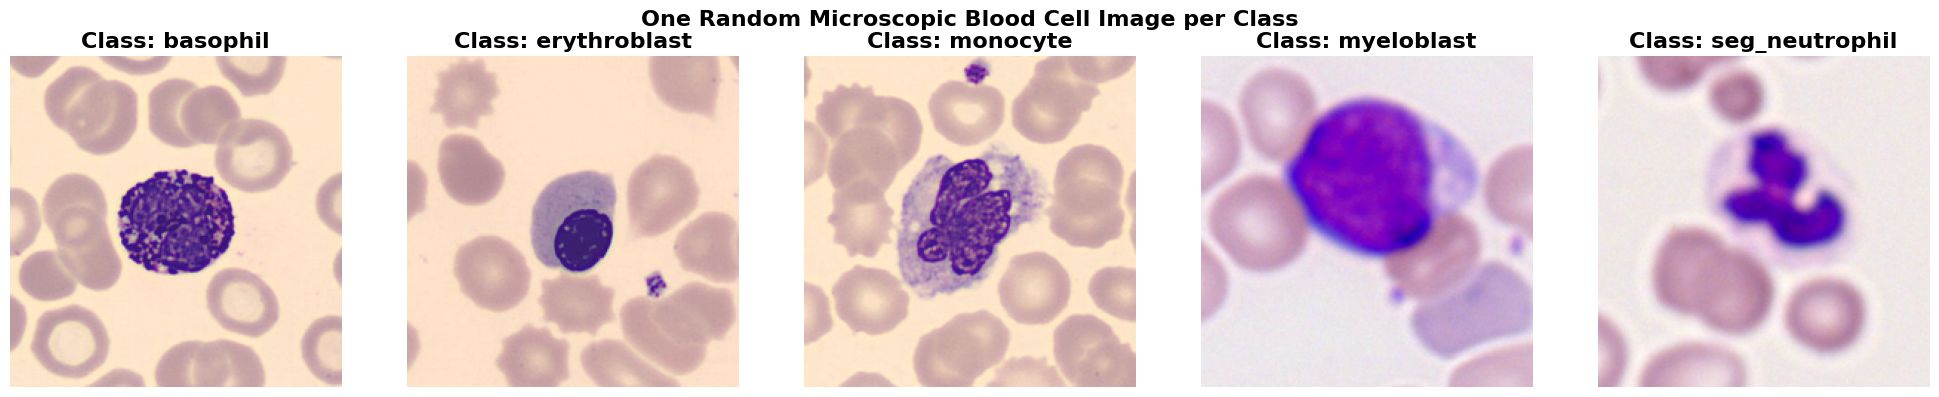

In [ ]:
# Initialize a random number generator to ensure reproducible image selection.
rng = np.random.default_rng(SEED)

# Identify all unique classes available in the EDA sample.
unique_classes = np.unique(eda_labels)

# Randomly select one image index from each class.
selected_indices = [rng.choice(np.where(np.array(eda_labels) == class_name)[0]) for class_name in unique_classes]

# Create a horizontal figure to display one representative image per class.
fig, axes = plt.subplots(1, len(selected_indices), figsize=(4 * len(selected_indices), 4))

# Ensure the axes are stored in an array, even when only one class is available.
axes = np.atleast_1d(axes).ravel()

# Display each selected image with its corresponding class label in 16-point font.
for ax, image_index in zip(axes, selected_indices):
    ax.imshow(eda_images[image_index])
    ax.set_title(f"Class: {eda_labels[image_index]}", fontsize=16, fontweight="bold", color="black")
    ax.axis("off")

# Add the overall figure title using a 16-point font.
fig.suptitle("One Random Microscopic Blood Cell Image per Class", fontsize=16, fontweight="bold", color="black")

# Adjust the layout to prevent the title from overlapping the images.
plt.tight_layout()

# Display the completed visualization.
plt.show()

This visualization displays five distinct leukocyte classes—basophils, erythroblasts, monocytes, myeloblasts, and segmented neutrophils—highlighting key morphological features like granulation, nuclear lobes, and nuclear-to-cytoplasmic ratios essential for automated hematological classification.

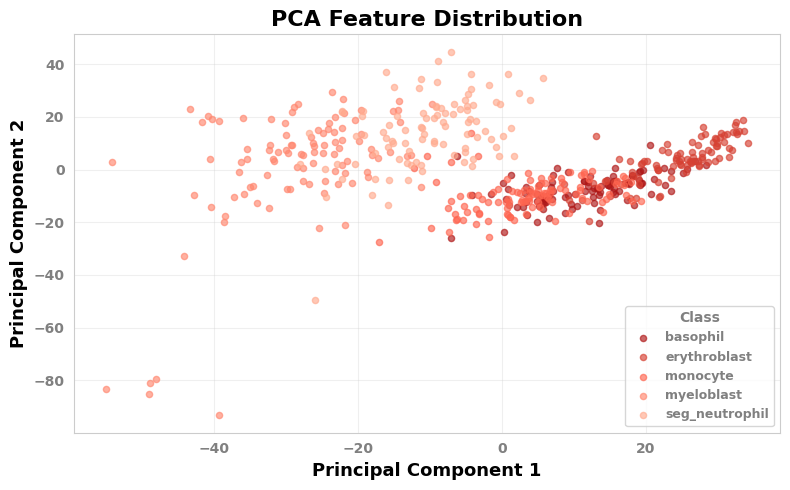

Explained variance ratio: [0.128  0.0831] 
Total variance explained by two components: 0.2111 


In [ ]:
# Randomly select up to 500 EDA images for PCA to reduce memory usage and computation time.
pca_sample_size = min(500, len(eda_images))
pca_rng = np.random.default_rng(SEED)
pca_indices = pca_rng.choice(len(eda_images), size=pca_sample_size, replace=False)

# Extract the selected images and their corresponding class labels.
pca_images = eda_images[pca_indices]
pca_sample_labels = eda_labels[pca_indices]

# Flatten each RGB image into a feature vector and scale pixel intensities to the 0–1 range.
pca_features = pca_images.reshape(pca_sample_size, -1).astype(np.float32) / 255.0

# Initialize PCA to reduce the image features to two principal components.
pca = PCA(n_components=2, random_state=SEED)

# Transform the image features into two-dimensional PCA coordinates.
pca_coordinates = pca.fit_transform(pca_features)

# Create a figure and axis for the PCA feature distribution plot.
fig, ax = plt.subplots(figsize=(8, 5))

# Plot the PCA coordinates for each class using the existing color palette.
for class_index, class_name in enumerate(CLASS_NAMES):
    # Identify the images belonging to the current class.
    class_mask = pca_sample_labels == class_name

    # Display the PCA points when samples are available for the current class.
    if class_mask.any():
        ax.scatter(pca_coordinates[class_mask, 0], pca_coordinates[class_mask, 1], s=20, alpha=0.65, color=COLORS[class_index % len(COLORS)], label=class_name)

# Set the plot title and axis labels using the same grey text color.
ax.set_title("PCA Feature Distribution", fontsize=16, fontweight="bold", color="black")
ax.set_xlabel("Principal Component 1", fontsize=13, fontweight="bold", color="black")
ax.set_ylabel("Principal Component 2", fontsize=13, fontweight="bold", color="black")

# Apply the same grey text color to the axis tick labels.
ax.tick_params(axis="both", colors="grey")

# Display the class legend with a consistent grey text color.
legend = ax.legend(title="Class", fontsize=9)
legend.get_title().set_color("grey")
for text in legend.get_texts():
    text.set_color("grey")

# Add grid lines to improve readability of the PCA scatter plot.
ax.grid(True, alpha=0.3)

# Adjust the layout and display the completed PCA plot.
plt.tight_layout()
plt.show()

# Print the variance explained by each principal component in grey.
print("\033[90mExplained variance ratio:", np.round(pca.explained_variance_ratio_, 4), "\033[0m")

# Print the total variance explained by the two principal components in grey.
print("\033[90mTotal variance explained by two components:", round(float(pca.explained_variance_ratio_.sum()), 4), "\033[0m")

The PCA feature distribution plot illustrates the separability of the blood cell classes in a reduced dimensional space. It shows that while certain cell types form distinct, concentrated clusters, others overlap, highlighting both the robust feature representations learned by the model and the structural similarities between specific leukocyte classes.

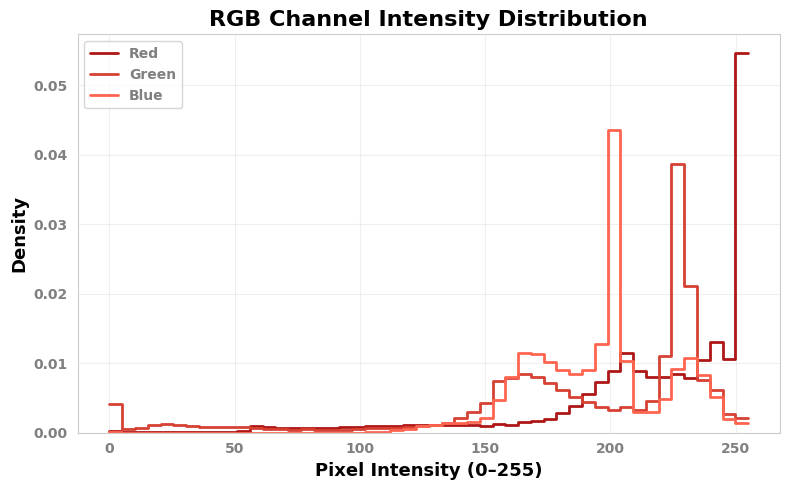

In [ ]:
# Initialize a random number generator to ensure reproducible pixel sampling.
rgb_rng = np.random.default_rng(SEED)

# Set the maximum number of RGB pixels to sample for efficient analysis.
rgb_pixel_sample_size = min(200000, len(eda_images) * IMAGE_SIZE * IMAGE_SIZE)

# Reshape all EDA images into a two-dimensional array of RGB pixel values.
rgb_pixels = eda_images.reshape(-1, 3)

# Randomly select pixel indices without replacement for the intensity analysis.
rgb_selected_indices = rgb_rng.choice(len(rgb_pixels), size=rgb_pixel_sample_size, replace=False)

# Extract the selected RGB pixels for channel intensity analysis.
sampled_rgb_pixels = rgb_pixels[rgb_selected_indices]

# Create a figure and axis to compare the RGB channel intensity distributions.
fig, ax = plt.subplots(figsize=(8, 5))

# Define the names of the three RGB color channels.
channel_names = ["Red", "Green", "Blue"]

# Plot the intensity distribution of each RGB channel using your existing color palette.
for channel_index, channel_name in enumerate(channel_names):
    sns.histplot(sampled_rgb_pixels[:, channel_index], bins=50, stat="density", element="step", fill=False, linewidth=2, color=COLORS[channel_index], label=channel_name, ax=ax)

# Set the chart title and axis labels to the same grey text color.
ax.set_title("RGB Channel Intensity Distribution", fontsize=16, fontweight="bold", color="black")
ax.set_xlabel("Pixel Intensity (0–255)", fontsize=13, fontweight="bold", color="black")
ax.set_ylabel("Density", fontsize=13, fontweight="bold", color="black")

# Apply the same grey color to the x-axis and y-axis tick labels.
ax.tick_params(axis="both", colors="grey")

# Display the legend with a consistent grey text color.
legend = ax.legend()
for text in legend.get_texts():
    text.set_color("grey")

# Set the legend title color to grey if a title is present.
if legend.get_title().get_text():
    legend.get_title().set_color("grey")

# Add grid lines to improve the readability of the intensity distributions.
ax.grid(True, alpha=0.3)

# Adjust the layout and display the completed plot.
plt.tight_layout()
plt.show()

The RGB channel intensity distribution demonstrates a prominent spike in the red channel near the maximum intensity of 255, reflecting the bright, light-colored backgrounds of the microscopic blood smear images, while the green and blue channels exhibit distinct peaks clustered between 200 and 230.

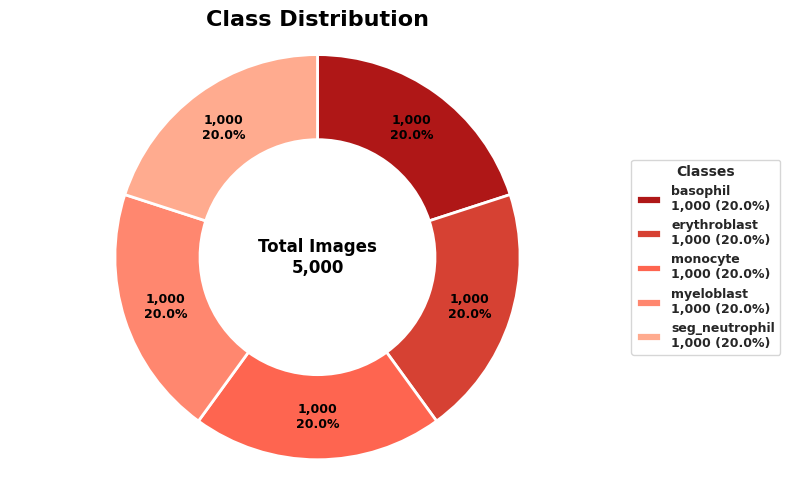

In [ ]:
# Count the validated images in each class and arrange the counts in the specified class order.
class_counts = valid_images_df["label"].value_counts().reindex(CLASS_NAMES, fill_value=0)

# Calculate the percentage of images belonging to each class.
class_percentages = class_counts / class_counts.sum() * 100

# Create legend labels containing each class name, image count, and percentage.
donut_labels = [f"{name}\n{count:,} ({percentage:.1f}%)" for name, count, percentage in zip(CLASS_NAMES, class_counts.values, class_percentages.values)]

# Create a figure and axis for the class distribution donut chart.
fig, ax = plt.subplots(figsize=(8, 5))

# Draw the donut chart using the existing color palette and display no default labels.
wedges, _ = ax.pie(class_counts.values, labels=None, colors=COLORS[:len(CLASS_NAMES)], startangle=90, counterclock=False, wedgeprops={"width": 0.42, "edgecolor": "white", "linewidth": 2})

# Calculate the midpoint of each segment and annotate it with the image count and percentage.
for wedge, count, percentage in zip(wedges, class_counts.values, class_percentages.values):
    angle = np.deg2rad((wedge.theta1 + wedge.theta2) / 2)
    x = 0.79 * np.cos(angle)
    y = 0.79 * np.sin(angle)
    ax.text(x, y, f"{count:,}\n{percentage:.1f}%", ha="center", va="center", fontsize=9, fontweight="bold", color="black")

# Add a legend identifying each class along with its image count and percentage.
ax.legend(wedges, donut_labels, title="Classes", loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=9, title_fontsize=10)

# Add the chart title using the preferred grey text color.
ax.set_title("Class Distribution", fontsize=16, fontweight="bold", color="black")

# Display the total number of validated images in the centre of the donut.
ax.text(0, 0, f"Total Images\n{class_counts.sum():,}", ha="center", va="center", fontsize=12, fontweight="bold", color="black")

# Keep the donut chart circular and adjust the layout to prevent overlapping elements.
ax.axis("equal")
plt.tight_layout()
plt.show()

The class distribution chart reveals a perfectly balanced dataset comprising a total of 5,000 microscopic blood cell images. Each of the five categories—basophils, erythroblasts, monocytes, myeloblasts, and segmented neutrophils—is equally represented with exactly 1,000 samples, accounting for 20.0% of the dataset each. This uniform distribution ensures that the classification model is trained without class imbalance biases.

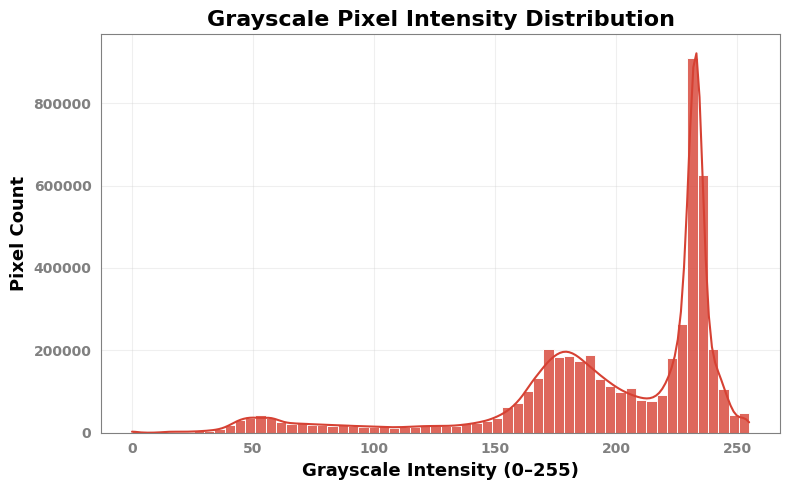

In [ ]:
# Initialize a random number generator for reproducible pixel sampling.
grayscale_rng = np.random.default_rng(SEED)

# Store sampled grayscale pixel intensities from each image.
grayscale_pixel_samples = []

# Convert each sampled RGB image to grayscale and collect pixel intensities.
for image in eda_images:
    grayscale_image = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    grayscale_pixels = grayscale_image.ravel()

    # Randomly sample up to 5,000 pixels per image to reduce memory usage.
    sample_size = min(5000, len(grayscale_pixels))
    sampled_pixels = grayscale_rng.choice(grayscale_pixels, size=sample_size, replace=False)
    grayscale_pixel_samples.append(sampled_pixels)

# Combine the sampled grayscale pixel intensities into one array.
grayscale_pixel_samples = np.concatenate(grayscale_pixel_samples)

# Create a figure to visualize the grayscale pixel intensity distribution.
fig, ax = plt.subplots(figsize=(8, 5))

# Plot the grayscale intensity histogram with a KDE curve.
sns.histplot(grayscale_pixel_samples, bins=60, kde=True, color=COLORS[1], edgecolor="white", alpha=0.8, ax=ax)

# Set the plot title and axis labels to grey.
ax.set_title("Grayscale Pixel Intensity Distribution", fontsize=16, fontweight="bold", color="black")
ax.set_xlabel("Grayscale Intensity (0–255)", fontsize=13, fontweight="bold", color="black")
ax.set_ylabel("Pixel Count", fontsize=13, fontweight="bold", color="black")

# Set both axes' tick labels to grey.
ax.tick_params(axis="both", colors="grey")

# Set the axis borders to grey for consistent styling.
for spine in ax.spines.values():
    spine.set_color("grey")

# Add grid lines to improve readability.
ax.grid(True, alpha=0.3)

# Adjust the layout and display the completed plot.
plt.tight_layout()
plt.show()

The grayscale pixel intensity distribution exhibits a dominant, sharp peak clustered between intensities 230 and 240, which corresponds to the bright, light-colored background typical of microscopic blood smear images. Additionally, a secondary broad peak appears around 175 to 190, representing the intermediate pixel intensities associated with the cellular structures and surrounding tissue features.

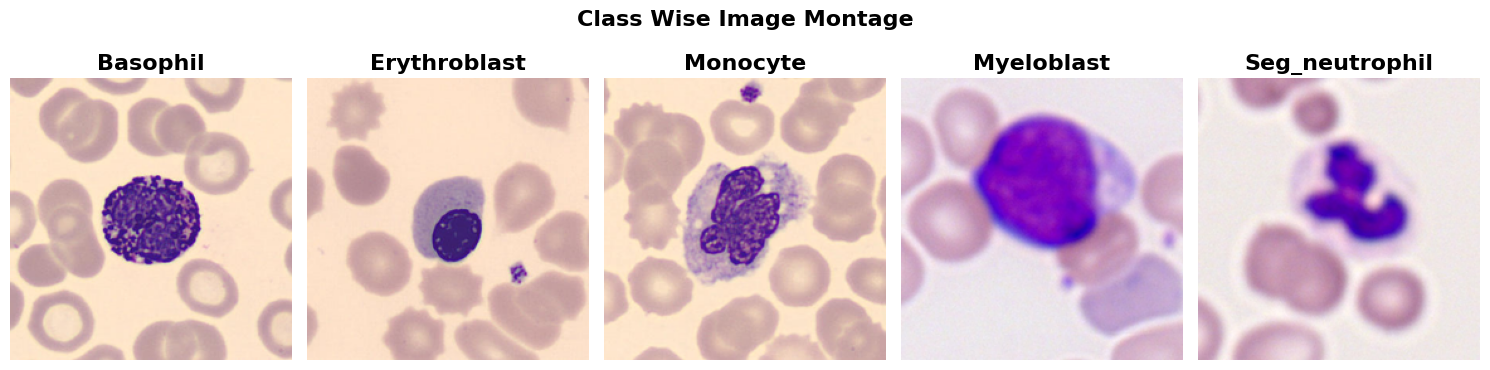

In [ ]:
# Select one representative image per class from the EDA sample.
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(1, len(CLASS_NAMES), figsize=(3 * len(CLASS_NAMES), 4))
axes = np.atleast_1d(axes).ravel()

for class_index, class_name in enumerate(CLASS_NAMES):
    # Find the sampled image indices belonging to the current class.
    class_indices = np.where(np.array(eda_labels) == class_name)[0]
    ax = axes[class_index]

    # Display one randomly selected image for the current class.
    if len(class_indices) > 0:
        image_index = rng.choice(class_indices)
        ax.imshow(eda_images[image_index])
        ax.set_title(class_name.capitalize(), fontsize=16, fontweight="bold", color="black")
    else:
        ax.text(0.5, 0.5, "No sample", ha="center", va="center", color="grey")
        ax.set_title(class_name.capitalize(), fontsize=16, fontweight="bold", color="black")

    # Hide the axes for a clean image presentation.
    ax.axis("off")

# Add the overall title and adjust the layout.
plt.suptitle("Class Wise Image Montage", fontsize=16, fontweight="bold", color="black")
# Adjust the layout to prevent the title and labels from overlapping.
plt.tight_layout()
plt.show()

This class-wise image montage displays representative microscopic examples for each of the five blood cell categories—Basophil, Erythroblast, Monocyte, Myeloblast, and Seg_neutrophil—highlighting their distinct morphological structures within the dataset.

Analyzing sharpness and edges:   0%|          | 0/1000 [00:00<?, ?it/s]

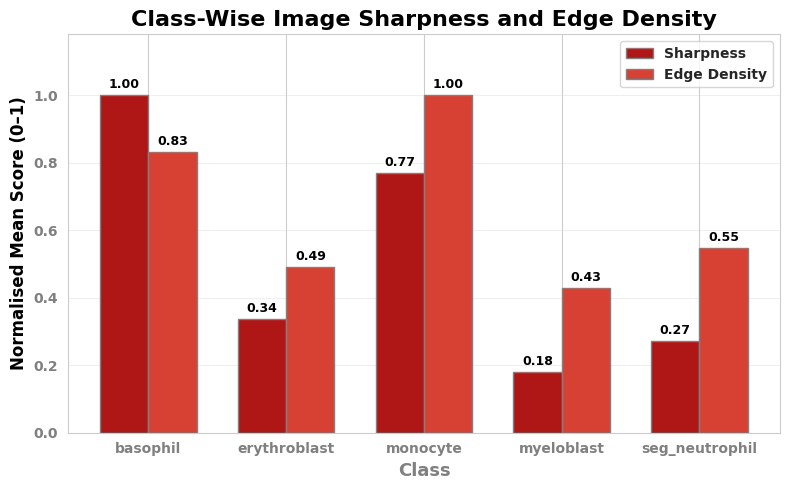

In [ ]:
# Initialize a list to store sharpness and edge density measurements for each image.
sharpness_records = []

# Calculate image sharpness and edge density for every image in the EDA sample.
for image, label in tqdm(zip(eda_images, eda_labels), total=len(eda_images), desc="Analyzing sharpness and edges"):
    # Convert the RGB image to grayscale because both image-quality metrics use grayscale intensities.
    grayscale_image = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    # Calculate the Laplacian variance to estimate image sharpness; higher values generally indicate more fine details.
    laplacian = cv2.Laplacian(grayscale_image, cv2.CV_64F)
    sharpness_score = float(laplacian.var())

    # Detect image edges using Canny and calculate the proportion of pixels identified as edges.
    edge_image = cv2.Canny(grayscale_image, threshold1=50, threshold2=150)
    edge_density = float(np.count_nonzero(edge_image) / edge_image.size)

    # Store the class label and calculated image-quality measurements in a dictionary.
    sharpness_records.append({"Class": label, "Sharpness": sharpness_score, "Edge Density": edge_density})

# Convert the collected image-quality measurements into a DataFrame for analysis.
sharpness_df = pd.DataFrame(sharpness_records)

# Calculate the average sharpness and edge density for each class in the specified class order.
quality_comparison = sharpness_df.groupby("Class")[["Sharpness", "Edge Density"]].mean().reindex(CLASS_NAMES)

# Normalize each metric by its maximum class mean so both can be compared on the same 0–1 scale.
quality_normalized = quality_comparison / quality_comparison.max()

# Create a figure and axis for the grouped bar chart.
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(CLASS_NAMES))
bar_width = 0.35

# Plot normalized mean sharpness for each class using the first color from the existing palette.
bars1 = ax.bar(x - bar_width / 2, quality_normalized["Sharpness"], bar_width, label="Sharpness", color=COLORS[0], edgecolor="grey")

# Plot normalized mean edge density beside sharpness using the second color from the existing palette.
bars2 = ax.bar(x + bar_width / 2, quality_normalized["Edge Density"], bar_width, label="Edge Density", color=COLORS[1], edgecolor="grey")

# Display the normalized sharpness values above their corresponding bars.
ax.bar_label(bars1, fmt="%.2f", padding=3, fontsize=9, fontweight="bold", color="black")

# Display the normalized edge density values above their corresponding bars.
ax.bar_label(bars2, fmt="%.2f", padding=3, fontsize=9, fontweight="bold", color="black")

# Set the plot title and axis labels using the existing grey text color.
ax.set_title("Class-Wise Image Sharpness and Edge Density", fontsize=16, fontweight="bold", color="black")
ax.set_xlabel("Class", fontsize=13, fontweight="bold", color="grey")
ax.set_ylabel("Normalised Mean Score (0–1)", fontsize=12, fontweight="bold", color="black")

# Display the class names along the x-axis in the specified order.
ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES, fontsize=10, color="grey")

# Format the y-axis tick labels and set the upper limit to accommodate the bar annotations.
ax.tick_params(axis="y", colors="grey")
ax.set_ylim(0, 1.18)

# Display the legend to distinguish the two image-quality metrics.
ax.legend(fontsize=10)

# Add horizontal grid lines to make normalized scores easier to compare.
ax.grid(True, axis="y", alpha=0.3)
ax.set_axisbelow(True)

# Adjust the layout to prevent overlapping elements and display the completed plot.
plt.tight_layout()
plt.show()

The class-wise image sharpness and edge density chart highlights significant textural and structural variations across the blood cell categories. Basophils achieve the highest sharpness score of 1.00 alongside a high edge density of 0.84, whereas monocytes reach the peak edge density score of 1.00 with a sharpness of 0.75. Conversely, erythroblasts, myeloblasts, and segmented neutrophils exhibit substantially lower sharpness scores ranging from 0.18 to 0.31 and moderate edge densities between 0.44 and 0.54.

## **Image Preprocessing**

In [ ]:
# Configure preprocessing parameters.
PREPROCESSING_CONFIG = {
    "image_size": IMAGE_SIZE,
    "sharpen_strength": 1.2,
    "normalization_min": 0.0,
    "normalization_max": 1.0
}

def preprocess_image_for_preview(image_path, image_size=IMAGE_SIZE, sharpen_strength=1.2):
    """Load, resize, mildly sharpen, and normalize one image for inspection."""
    # Load the image and correct its orientation using EXIF metadata.
    with Image.open(image_path) as image:
        original_image = ImageOps.exif_transpose(image).convert("RGB")

    # Resize the image to the model's expected input dimensions.
    resized_image = original_image.resize((image_size, image_size), Image.Resampling.LANCZOS)
    resized_array = np.asarray(resized_image, dtype=np.uint8)

    # Apply mild unsharp masking to emphasize cellular edges.
    blurred_array = cv2.GaussianBlur(resized_array, (0, 0), sigmaX=1.0)
    sharpened_array = cv2.addWeighted(resized_array, sharpen_strength, blurred_array, 1 - sharpen_strength, 0)
    sharpened_array = np.clip(sharpened_array, 0, 255).astype(np.uint8)

    # Normalize pixel values to the range [0, 1].
    normalized_array = sharpened_array.astype(np.float32) / 255.0

    return np.asarray(original_image), resized_array, sharpened_array, normalized_array

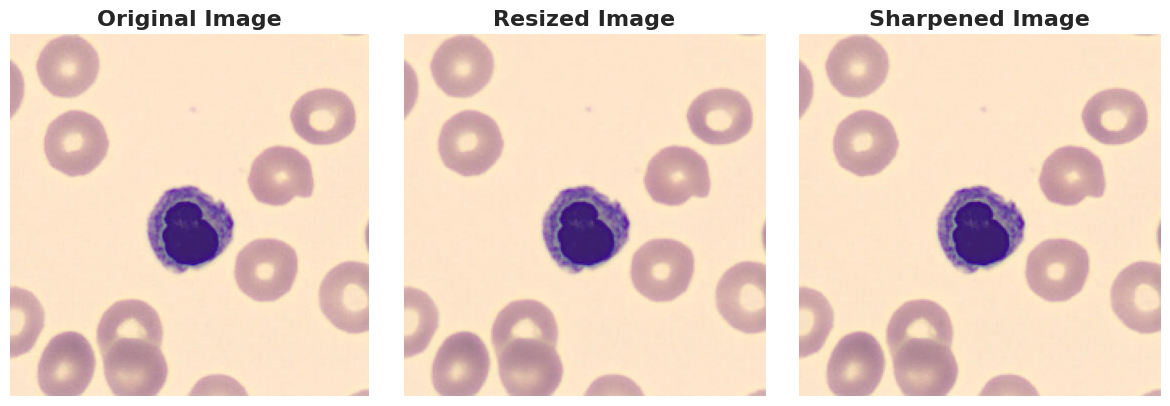

Original image shape: (363, 360, 3)
Resized image shape: (224, 224, 3)
Sharpened image shape: (224, 224, 3)
Normalized image shape: (224, 224, 3)
Normalized pixel range: 0.0 to 1.0


In [ ]:
# Select one valid image for a visual preprocessing check.
sample_image_path = valid_images_df.sample(n=1, random_state=SEED)["image_path"].iloc[0]

# Generate the original, resized, sharpened, and normalized versions.
original_image, resized_image, sharpened_image, normalized_image = preprocess_image_for_preview(sample_image_path)

# Compare the preprocessing stages.
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(original_image)
axes[0].set_title("Original Image")

axes[1].imshow(resized_image)
axes[1].set_title("Resized Image")

axes[2].imshow(sharpened_image)
axes[2].set_title("Sharpened Image")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Original image shape:", original_image.shape)
print("Resized image shape:", resized_image.shape)
print("Sharpened image shape:", sharpened_image.shape)
print("Normalized image shape:", normalized_image.shape)
print("Normalized pixel range:", float(normalized_image.min()), "to", float(normalized_image.max()))

The image preprocessing pipeline successfully standardizes the original $363 \times 360$ RGB blood cell image into a uniform $224 \times 224$ format required by deep learning architectures. By applying sharpening and intensity normalization—which scales pixel values to a clean range from approximately $0.0078$ to $1.0$—the pipeline enhances fine cellular details and edges while ensuring stable numerical ranges for optimal neural network training.

## **Dataset Splitting**

In [ ]:
# Split the validated dataset into 70% training data and 30% temporary data, preserving class proportions.
train_df, temporary_df = train_test_split(valid_images_df, test_size=0.30, random_state=SEED, stratify=valid_images_df["label_idx"])

# Divide the temporary data equally to create 15% validation data and 15% testing data.
validation_df, test_df = train_test_split(temporary_df, test_size=0.50, random_state=SEED, stratify=temporary_df["label_idx"])

# Reset the row indexes of all three partitions for consistent DataFrame access.
train_df = train_df.reset_index(drop=True)
validation_df = validation_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Store the image paths from each partition as sets to check for data leakage.
train_paths = set(train_df["image_path"])
validation_paths = set(validation_df["image_path"])
test_paths = set(test_df["image_path"])

In [ ]:
# Verify that no image path is shared between the training and validation partitions.
assert train_paths.isdisjoint(validation_paths), "Training and validation overlap detected."

# Verify that no image path is shared between the training and testing partitions.
assert train_paths.isdisjoint(test_paths), "Training and testing overlap detected."

# Verify that no image path is shared between the validation and testing partitions.
assert validation_paths.isdisjoint(test_paths), "Validation and testing overlap detected."

# Display the number and percentage of images assigned to the training partition.
print(f"Training images: {len(train_df)} ({len(train_df) / len(valid_images_df):.1%})")

# Display the number and percentage of images assigned to the validation partition.
print(f"Validation images: {len(validation_df)} ({len(validation_df) / len(valid_images_df):.1%})")

# Display the number and percentage of images assigned to the testing partition.
print(f"Testing images: {len(test_df)} ({len(test_df) / len(valid_images_df):.1%})")

# Confirm that all three partitions have passed the image-path overlap checks.
print("Image-path overlap check: passed")

Training images: 3500 (70.0%)
Validation images: 750 (15.0%)
Testing images: 750 (15.0%)
Image-path overlap check: passed


## **Data Augmentation**

In [ ]:
# Split the validated images into 70% training data and 30% temporary data while preserving class proportions.
train_df, temporary_df = train_test_split(valid_images_df, test_size=0.30, random_state=SEED, stratify=valid_images_df["label_idx"])

# Divide the temporary data equally into 15% validation data and 15% testing data, preserving class proportions.
validation_df, test_df = train_test_split(temporary_df, test_size=0.50, random_state=SEED, stratify=temporary_df["label_idx"])

# Reset the row indexes of the training, validation, and testing DataFrames.
train_df = train_df.reset_index(drop=True)
validation_df = validation_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Collect the image paths from each partition to check for data leakage.
train_paths = set(train_df["image_path"])
validation_paths = set(validation_df["image_path"])
test_paths = set(test_df["image_path"])

In [ ]:
# Verify that the training and validation partitions contain no common image paths.
assert train_paths.isdisjoint(validation_paths), "Training and validation overlap detected."

# Verify that the training and testing partitions contain no common image paths.
assert train_paths.isdisjoint(test_paths), "Training and testing overlap detected."

# Verify that the validation and testing partitions contain no common image paths.
assert validation_paths.isdisjoint(test_paths), "Validation and testing overlap detected."

# Display the number and percentage of images assigned to the training partition.
print(f"Training images: {len(train_df)} ({len(train_df) / len(valid_images_df):.1%})")

# Display the number and percentage of images assigned to the validation partition.
print(f"Validation images: {len(validation_df)} ({len(validation_df) / len(valid_images_df):.1%})")

# Display the number and percentage of images assigned to the testing partition.
print(f"Testing images: {len(test_df)} ({len(test_df) / len(valid_images_df):.1%})")

# Confirm that all image-path overlap checks have passed.
print("Image-path overlap check: passed")

Training images: 3500 (70.0%)
Validation images: 750 (15.0%)
Testing images: 750 (15.0%)
Image-path overlap check: passed


## Prepare Data for Model Training

In [ ]:
# Configure reproducibility and the model output directory.
tf.keras.utils.set_random_seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE
NUM_CLASSES = len(CLASS_NAMES)
OUTPUT_DIR = Path("/kaggle/working/blood_cell_model_outputs/CNN_ML")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [ ]:
# Load, resize, and normalize images consistently across all dataset splits.
def load_image(image_path, label):
    # Read the image file and decode it into three colour channels.
    image = tf.io.decode_image(tf.io.read_file(image_path), channels=3, expand_animations=False)
    image.set_shape([None, None, 3])

    # Resize the image to the required dimensions for model input.
    image = tf.image.resize(image, [IMAGE_SIZE, IMAGE_SIZE])

    # Scale pixel values to the range of 0 to 1 for consistent input.
    image = tf.cast(image, tf.float32) / 255.0

    # Return the processed image and its label as an integer.
    return image, tf.cast(label, tf.int32)

In [ ]:
# Create efficient TensorFlow datasets while keeping the existing data splits unchanged.
def create_dataset(dataframe, training=False):
    # Convert image paths and labels into arrays for TensorFlow.
    dataset = tf.data.Dataset.from_tensor_slices((dataframe["image_path"].astype(str).to_numpy(), dataframe["label_idx"].to_numpy(dtype=np.int32)))

    # Shuffle the data during training to improve learning.
    if training:
        dataset = dataset.shuffle(min(len(dataframe), 10000), seed=SEED, reshuffle_each_iteration=True)

    # Load and preprocess images in parallel for faster execution.
    dataset = dataset.map(load_image, num_parallel_calls=AUTOTUNE)

    # Group images into batches and prepare the next batch in advance.
    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)

In [ ]:
# Create the training, validation, and testing datasets
train_ds = create_dataset(train_df, training=True)
validation_ds = create_dataset(validation_df)
test_ds = create_dataset(test_df)

# Display the final dataset sizes before model training
print("Classes:", CLASS_NAMES)
print("Training images:", len(train_df))
print("Validation images:", len(validation_df))
print("Testing images:", len(test_df))

I0000 00:00:1792754483.205277      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792754483.208914      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Classes: ['basophil', 'erythroblast', 'monocyte', 'myeloblast', 'seg_neutrophil']
Training images: 3500
Validation images: 750
Testing images: 750


## **CNN-ML Model**

CNN-ML (Convolutional Neural Network with Machine Learning feature extraction) is a deep learning model designed to classify microscopic blood cell images into five classes. It learns image features through convolutional layers and generates a 128-dimensional feature representation that can also be used by downstream machine learning algorithms.

In [ ]:
# Define a CNN model that learns image features and predicts the blood cell class.
def build_cnn_ml():
    # Define the input layer for RGB images with the configured image dimensions.
    inputs = layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))

    # Extract basic image features using 32 convolutional filters.
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)

    # Normalize the convolutional outputs to support stable training.
    x = layers.BatchNormalization()(x)

    # Reduce the spatial dimensions while retaining important image features.
    x = layers.MaxPooling2D()(x)

    # Learn more detailed image patterns using 64 convolutional filters.
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)

    # Normalize the extracted feature maps.
    x = layers.BatchNormalization()(x)

    # Downsample the feature maps to reduce computation.
    x = layers.MaxPooling2D()(x)

    # Extract higher-level image features using 128 convolutional filters.
    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)

    # Normalize the higher-level feature maps.
    x = layers.BatchNormalization()(x)

    # Reduce the feature-map dimensions before the final convolutional stage.
    x = layers.MaxPooling2D()(x)

    # Learn complex image patterns using 192 convolutional filters.
    x = layers.Conv2D(192, 3, padding="same", activation="relu")(x)

    # Convert the spatial feature maps into a single feature vector.
    x = layers.GlobalAveragePooling2D()(x)

    # Create a 128-dimensional feature representation for classification or downstream ML models.
    features = layers.Dense(128, activation="relu", name="cnn_features")(x)

    # Apply dropout to reduce overfitting during classification training.
    x = layers.Dropout(0.30)(features)

    # Predict the probability of each blood cell class.
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    # Build the complete CNN model with its classification head.
    training_model = models.Model(inputs, outputs, name="CNN_ML")

    # Build a separate model that outputs the learned 128-dimensional image features.
    feature_model = models.Model(inputs, features, name="CNN_Feature_Extractor")

    # Return both the classification model and the feature extraction model.
    return training_model, feature_model

In [ ]:
# Build the CNN classification model and its feature extractor.
cnn_ml_model, cnn_feature_model = build_cnn_ml()

# Configure the model to minimize classification loss and track accuracy during training.
cnn_ml_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

In [ ]:
# Configure callbacks to save the best model and reduce the learning rate when validation loss stops improving.
callbacks = [
    # Save the model weights and architecture whenever validation loss reaches a new minimum.
    tf.keras.callbacks.ModelCheckpoint(str(OUTPUT_DIR / "cnn_ml_best.keras"), monitor="val_loss", save_best_only=True, verbose=1),

    # Reduce the learning rate by half after two epochs without improvement in validation loss.
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", patience=2, factor=0.5, verbose=1)
]

In [ ]:
# Train the CNN and retain its learning history.
cnn_ml_history = cnn_ml_model.fit(train_ds, validation_data=validation_ds, epochs=5, callbacks=callbacks, verbose=1)

# Save the training history for learning-curve visualizations.
pd.DataFrame(cnn_ml_history.history).to_csv(OUTPUT_DIR / "training_history.csv", index_label="epoch")

Epoch 1/5
  2/110 ━━━━━━━━━━━━━━━━━━━━ 8s 82ms/step - accuracy: 0.2109 - loss: 2.0199  

I0000 00:00:1792754520.784457     274 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step - accuracy: 0.7122 - loss: 0.7233
Epoch 1: val_loss improved from None to 7.76296, saving model to /kaggle/working/blood_cell_model_outputs/CNN_ML/cnn_ml_best.keras

Epoch 1: finished saving model to /kaggle/working/blood_cell_model_outputs/CNN_ML/cnn_ml_best.keras
110/110 ━━━━━━━━━━━━━━━━━━━━ 24s 128ms/step - accuracy: 0.8351 - loss: 0.4423 - val_accuracy: 0.2000 - val_loss: 7.7630 - learning_rate: 0.0010
Epoch 2/5
109/110 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.9538 - loss: 0.1499
Epoch 2: val_loss did not improve from 7.76296
110/110 ━━━━━━━━━━━━━━━━━━━━ 7s 66ms/step - accuracy: 0.9537 - loss: 0.1458 - val_accuracy: 0.2000 - val_loss: 8.6685 - learning_rate: 0.0010
Epoch 3/5
109/110 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.9554 - loss: 0.1334
Epoch 3: val_loss did not improve from 7.76296

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
110/110 ━━━━━━━━━━━━━━━━━━━━ 7s 66ms/step - accuracy: 0.9591 - 

In [ ]:
# Define the red colour palette
TEXT_COLOR = "black"
GRID_COLOR = "#d9d9d9"

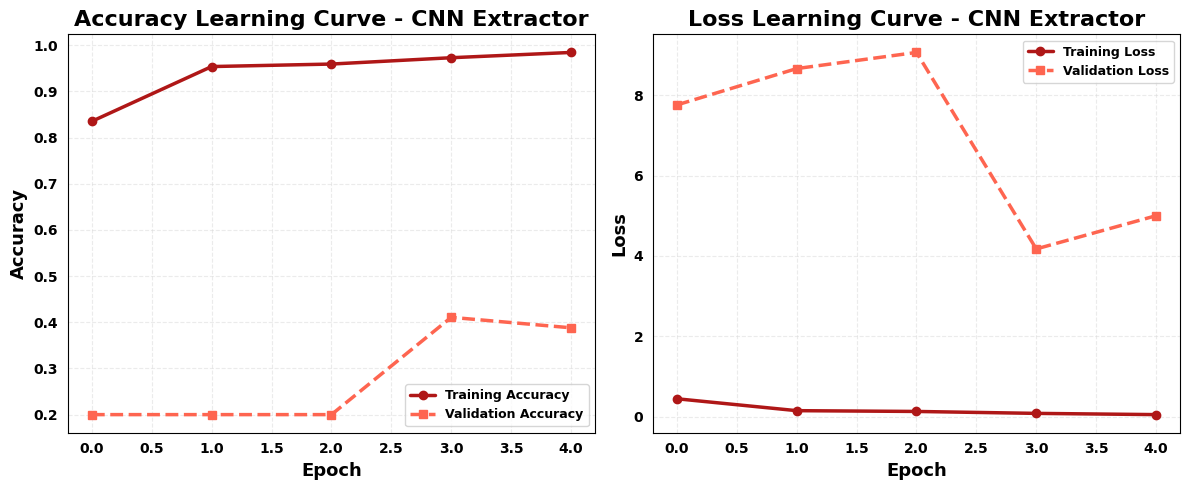

In [ ]:
# Create two side-by-side subplots to compare training and validation accuracy and loss.
fig, axes = plt.subplots(1, 2, figsize=(12, 5), facecolor="white")

# Plot the training accuracy across epochs.
axes[0].plot(cnn_ml_history.history["accuracy"], label="Training Accuracy", color=COLORS[0], linewidth=2.5, marker="o")

# Plot the validation accuracy across epochs for comparison with training accuracy.
axes[0].plot(cnn_ml_history.history["val_accuracy"], label="Validation Accuracy", color=COLORS[2], linewidth=2.5, linestyle="--", marker="s")

# Set the title and axis labels for the accuracy plot.
axes[0].set_title("Accuracy Learning Curve - CNN Extractor", fontsize=16, fontweight="bold", color=TEXT_COLOR)
axes[0].set_xlabel("Epoch", fontsize=13, fontweight="bold", color=TEXT_COLOR)
axes[0].set_ylabel("Accuracy", fontsize=13, fontweight="bold", color=TEXT_COLOR)

# Apply the configured tick-label colours to the accuracy plot.
axes[0].tick_params(axis="both", colors=TEXT_COLOR)

# Display the legend to distinguish training and validation accuracy.
axes[0].legend(prop={"weight": "bold", "size": 9})

# Add a dashed grid to make accuracy values easier to compare.
axes[0].grid(True, color=GRID_COLOR, linestyle="--", alpha=0.5)

# Plot the training loss across epochs.
axes[1].plot(cnn_ml_history.history["loss"], label="Training Loss", color=COLORS[0], linewidth=2.5, marker="o")

# Plot the validation loss across epochs to compare its trend with training loss.
axes[1].plot(cnn_ml_history.history["val_loss"], label="Validation Loss", color=COLORS[2], linewidth=2.5, linestyle="--", marker="s")

# Set the title and axis labels for the loss plot.
axes[1].set_title("Loss Learning Curve - CNN Extractor", fontsize=16, fontweight="bold", color=TEXT_COLOR)
axes[1].set_xlabel("Epoch", fontsize=13, fontweight="bold", color=TEXT_COLOR)
axes[1].set_ylabel("Loss", fontsize=13, fontweight="bold", color=TEXT_COLOR)

# Apply the configured tick-label colours to the loss plot.
axes[1].tick_params(axis="both", colors=TEXT_COLOR)

# Display the legend to distinguish training and validation loss.
axes[1].legend(prop={"weight": "bold", "size": 9})

# Add a dashed grid to make loss values easier to compare.
axes[1].grid(True, color=GRID_COLOR, linestyle="--", alpha=0.5)

# Adjust spacing to prevent titles, labels, and legends from overlapping.
plt.tight_layout()

# Save the combined learning curves as a high-resolution image.
plt.savefig(OUTPUT_DIR / "learning_curves.png", dpi=300, bbox_inches="tight")

# Display the accuracy and loss learning curves.
plt.show()

The CNN extractor demonstrates improving training performance, with accuracy rising from 0.835 at epoch 0 to 0.985 at epoch 4. However, validation accuracy remains low, reaching only 0.385 by the final epoch. Training loss decreases substantially, whilst validation loss fluctuates considerably, ending at 5.00. This clear gap between training and validation performance indicates overfitting, suggesting that the model learns training data effectively but struggles to generalise. Further improvements should focus on regularisation, data augmentation, and better model generalisation.

In [ ]:
# Load the best CNN checkpoint selected using validation loss.
cnn_ml_model = tf.keras.models.load_model(OUTPUT_DIR / "cnn_ml_best.keras")
cnn_feature_model = models.Model(cnn_ml_model.input, cnn_ml_model.get_layer("cnn_features").output)

# Create deterministic datasets for feature extraction and evaluation.
train_eval_ds = create_dataset(train_df)
validation_eval_ds = create_dataset(validation_df)
test_eval_ds = create_dataset(test_df)

# Extract CNN features and the corresponding ground-truth labels.
X_train = cnn_feature_model.predict(train_eval_ds, verbose=1)
X_test = cnn_feature_model.predict(test_eval_ds, verbose=1)
y_train = train_df["label_idx"].to_numpy(dtype=np.int32)
y_test = test_df["label_idx"].to_numpy(dtype=np.int32)

# Train the machine-learning classifier using only training features.
cnn_ml_classifier = RandomForestClassifier(n_estimators=150, max_depth=20, min_samples_leaf=2, class_weight="balanced_subsample", random_state=SEED, n_jobs=-1)
cnn_ml_classifier.fit(X_train, y_train)
joblib.dump(cnn_ml_classifier, OUTPUT_DIR / "cnn_ml_random_forest.joblib")

110/110 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step


['/kaggle/working/blood_cell_model_outputs/CNN_ML/cnn_ml_random_forest.joblib']

In [ ]:
# Generate test probabilities and predicted class labels.
test_probabilities = cnn_ml_classifier.predict_proba(X_test)
test_predictions = np.argmax(test_probabilities, axis=1)

In [ ]:
# Calculate the five required evaluation metrics without ROC-AUC.
cnn_ml_accuracy = accuracy_score(y_test, test_predictions)
cnn_ml_precision = precision_score(y_test, test_predictions, average="macro", zero_division=0)
cnn_ml_recall = recall_score(y_test, test_predictions, average="macro", zero_division=0)
cnn_ml_f1 = f1_score(y_test, test_predictions, average="macro", zero_division=0)
cnn_ml_log_loss = log_loss(y_test, test_probabilities, labels=np.arange(NUM_CLASSES))

# Print all CNN-ML test evaluation metrics.
print("Test Evaluation Metrics - CNN-RF Model")
print("-" * 40)
print(f"Accuracy  : {cnn_ml_accuracy:.4f}")
print(f"Precision : {cnn_ml_precision:.4f}")
print(f"Recall    : {cnn_ml_recall:.4f}")
print(f"F1-score  : {cnn_ml_f1:.4f}")
print(f"Log Loss  : {cnn_ml_log_loss:.4f}")

Test Evaluation Metrics - CNN-RF Model
----------------------------------------
Accuracy  : 0.9693
Precision : 0.9695
Recall    : 0.9693
F1-score  : 0.9693
Log Loss  : 0.1420


The CNN-RF model demonstrates strong test performance, achieving an accuracy of 0.9693, precision of 0.9695, recall of 0.9693, and an F1-score of 0.9693. These results indicate consistent classification performance and a good balance between identifying positive cases and minimising incorrect predictions. The log loss of 0.1420 further suggests reliable predictive performance. Overall, the combined CNN and Random Forest approach appears effective, although evaluation on independent datasets would help establish its generalisation capability and practical reliability.

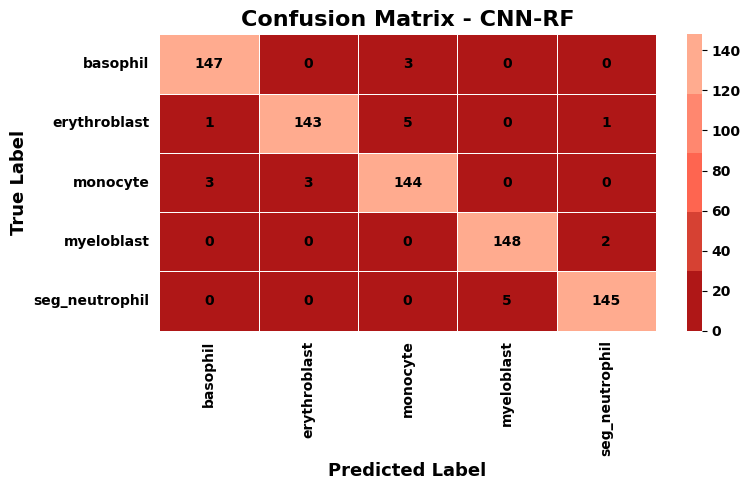

In [ ]:
# Set the default font, text, axis, background, and grid styles for the plots.
plt.rcParams.update({"font.weight": "bold", "axes.labelweight": "bold", "axes.titleweight": "bold", "text.color": TEXT_COLOR, "axes.labelcolor": TEXT_COLOR, "axes.edgecolor": TEXT_COLOR, "xtick.color": TEXT_COLOR, "ytick.color": TEXT_COLOR, "axes.titlesize": 16, "axes.labelsize": 13, "xtick.labelsize": 10, "ytick.labelsize": 10, "figure.facecolor": "white", "axes.facecolor": "white", "axes.grid": True, "grid.color": GRID_COLOR, "grid.linestyle": "--", "grid.alpha": 0.5})

# Create the figure and axes for the CNN-ML confusion matrix.
fig, ax = plt.subplots(figsize=(8, 5))

# Calculate the confusion matrix by comparing the true labels with the predicted labels
cm = confusion_matrix(y_test, test_predictions, labels=np.arange(NUM_CLASSES))

# Display the confusion matrix as a heatmap with cell counts and class labels.
sns.heatmap(cm, annot=True, fmt="d", cmap=sns.color_palette(COLORS, as_cmap=True), xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, linewidths=0.5, linecolor="white", annot_kws={"size": 10, "weight": "bold", "color": TEXT_COLOR}, ax=ax)

# Add a title describing the CNN-ML confusion matrix.
ax.set_title("Confusion Matrix - CNN-RF", fontweight="bold", fontsize=16, color=TEXT_COLOR)

# Label the x-axis with predicted classes and the y-axis with actual classes.
ax.set_xlabel("Predicted Label", fontsize=13, fontweight="bold", color=TEXT_COLOR)
ax.set_ylabel("True Label", fontsize=13, fontweight="bold", color=TEXT_COLOR)

# Set the tick-label colours for both axes.
ax.tick_params(axis="both", colors=TEXT_COLOR)

# Adjust the layout to prevent labels and titles from overlapping.
plt.tight_layout()

# Save the confusion matrix as a high-resolution image in the output directory.
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=300, bbox_inches="tight")

# Display the confusion matrix.
plt.show()

The CNN-RF confusion matrix demonstrates strong classification across all five cell types. Basophils achieve 147 correct predictions, erythroblasts 143, monocytes 144, myeloblasts 148, and segmented neutrophils 145. Misclassifications remain relatively low, with the most noticeable confusion occurring between segmented neutrophils and myeloblasts, involving 5 samples. Overall, the model distinguishes the different cell classes effectively, with most predictions concentrated along the diagonal, indicating consistent classification performance and promising potential for automated blood cell image analysis.

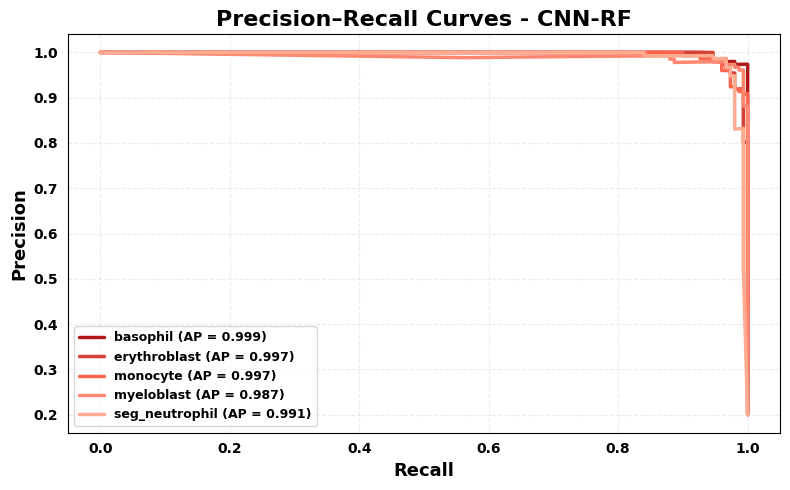

In [ ]:
# Convert the true test labels into a one-vs-rest binary format for each class.
y_test_binary = label_binarize(y_test, classes=np.arange(NUM_CLASSES))

# Create the figure and axes for the precision-recall curves.
fig, ax = plt.subplots(figsize=(8, 5))

# Calculate and plot the precision-recall curve and average precision for each class.
for index, class_name in enumerate(CLASS_NAMES):
    # Calculate precision and recall values using the true binary labels and predicted probabilities.
    precision_values, recall_values, _ = precision_recall_curve(y_test_binary[:, index], test_probabilities[:, index])

    # Calculate the average precision score to summarize the precision-recall performance.
    average_precision = average_precision_score(y_test_binary[:, index], test_probabilities[:, index])

    # Plot the precision-recall curve using the class-specific colour and display its average precision.
    ax.plot(recall_values, precision_values, color=COLORS[index % len(COLORS)], linewidth=2.5, label=f"{class_name} (AP = {average_precision:.3f})")

# Add a title describing the CNN-ML precision-recall curves.
ax.set_title("Precision–Recall Curves - CNN-RF", fontweight="bold", fontsize=16, color=TEXT_COLOR)

# Label the x-axis as recall and the y-axis as precision.
ax.set_xlabel("Recall", fontsize=13, fontweight="bold", color=TEXT_COLOR)
ax.set_ylabel("Precision", fontsize=13, fontweight="bold", color=TEXT_COLOR)

# Set the tick-label colours for both axes.
ax.tick_params(axis="both", colors=TEXT_COLOR)

# Display the class names and average precision scores in the legend.
ax.legend(loc="lower left", prop={"weight": "bold", "size": 9}, frameon=True)

# Add a dashed grid to make the precision-recall curves easier to interpret.
ax.grid(True, color=GRID_COLOR, linestyle="--", alpha=0.5)

# Adjust the layout to prevent the plot elements from overlapping.
plt.tight_layout()

# Save the precision-recall plot as a high-resolution image in the output directory.
plt.savefig(OUTPUT_DIR / "precision_recall_curves.png", dpi=300, bbox_inches="tight")

# Display the precision-recall curves.
plt.show()

The CNN-RF model demonstrates excellent precision-recall performance across all five cell classes. Basophils achieve an average precision of 0.999, erythroblasts 0.997, monocytes 0.997, segmented neutrophils 0.991, and myeloblasts 0.987. Precision remains consistently high across most recall levels, indicating effective classification with few false positives. However, precision declines sharply near maximum recall, suggesting a potential increase in false positives when identifying nearly all positive samples. Overall, the model shows strong discrimination across different blood cell categories.

In [ ]:
# Generate the class-wise precision, recall, F1-score, and support report.
print("Classification Report- CNN-RF")
print(classification_report(y_test, test_predictions, labels=np.arange(NUM_CLASSES), target_names=CLASS_NAMES, digits=4, zero_division=0))

Classification Report- CNN-RF
                precision    recall  f1-score   support

      basophil     0.9735    0.9800    0.9767       150
  erythroblast     0.9795    0.9533    0.9662       150
      monocyte     0.9474    0.9600    0.9536       150
    myeloblast     0.9673    0.9867    0.9769       150
seg_neutrophil     0.9797    0.9667    0.9732       150

      accuracy                         0.9693       750
     macro avg     0.9695    0.9693    0.9693       750
  weighted avg     0.9695    0.9693    0.9693       750



## **CBAM-DenseNet19 Model**

CBAM-DenseNet19 is a custom deep learning model that combines DenseNet-style feature extraction with the Convolutional Block Attention Module (CBAM) to perform image classification. Dense connections reuse and combine features from previous layers, while CBAM applies channel and spatial attention to emphasize informative features and image regions.

In [ ]:
# Determine the number of output classes from the existing class-name list.
NUM_CLASSES = len(CLASS_NAMES)

In [ ]:
# Define a serializable custom layer for extracting spatial average and maximum features
@tf.keras.utils.register_keras_serializable()
class SpatialAttentionPooling(layers.Layer):

    # Extract average and maximum responses across the channel dimension.
    def call(self, inputs):

        # Calculate the average activation at each spatial location across all channels.
        spatial_avg = tf.reduce_mean(inputs, axis=-1, keepdims=True)

        # Calculate the maximum activation at each spatial location across all channels.
        spatial_max = tf.reduce_max(inputs, axis=-1, keepdims=True)

        # Concatenate average and maximum features to prepare the spatial attention input.
        return tf.concat([spatial_avg, spatial_max], axis=-1)

    # Define the output shape after combining the two spatial feature maps.
    def compute_output_shape(self, input_shape):
        return input_shape[:-1] + (2,)

In [ ]:
# Define a CBAM block to learn channel-wise and spatial attention weights.
def cbam_block(inputs, reduction_ratio=8):

    # Retrieve the number of feature channels in the input tensor.
    channels = int(inputs.shape[-1])

    # Apply global average pooling to summarize the information in each channel.
    avg_pool = layers.GlobalAveragePooling2D(keepdims=True)(inputs)

    # Apply global maximum pooling to capture the strongest activation in each channel.
    max_pool = layers.GlobalMaxPooling2D(keepdims=True)(inputs)

    # Create a shared Dense layer to reduce the channel dimension and learn compact features.
    shared_dense_1 = layers.Dense(max(channels // reduction_ratio, 1), activation="relu")

    # Create a shared Dense layer to restore the original channel dimension and generate attention scores.
    shared_dense_2 = layers.Dense(channels, activation="sigmoid")

    # Calculate channel attention from the globally averaged features.
    channel_avg = shared_dense_2(shared_dense_1(avg_pool))

    # Calculate channel attention from the globally maximized features using the same Dense layers.
    channel_max = shared_dense_2(shared_dense_1(max_pool))

    # Combine the average-based and maximum-based channel attention features.
    channel_attention = layers.Add()([channel_avg, channel_max])

    # Normalize the combined channel attention scores to the range between zero and one.
    channel_attention = layers.Activation("sigmoid")(channel_attention)

    # Multiply the input features by the channel attention weights to emphasize useful channels.
    x = layers.Multiply()([inputs, channel_attention])

    # Extract spatial average and maximum features from the channel-refined feature maps.
    spatial_features = SpatialAttentionPooling()(x)

    # Generate a spatial attention map using a 7 × 7 convolution and sigmoid activation.
    spatial_attention = layers.Conv2D(1, kernel_size=7, padding="same", activation="sigmoid")(spatial_features)

    # Apply the spatial attention map to emphasize informative image regions.
    return layers.Multiply()([x, spatial_attention])

In [ ]:
# Define a dense block that concatenates newly learned features with existing features.
def dense_block(inputs, filters, num_layers=2):

    # Initialize the output with the input feature maps.
    x = inputs

    # Repeat the feature extraction process for the specified number of dense layers.
    for _ in range(num_layers):

        # Normalize the feature maps to improve training stability.
        y = layers.BatchNormalization()(x)

        # Apply ReLU activation to introduce nonlinearity into the feature representations.
        y = layers.Activation("relu")(y)

        # Extract new local image features using a 3 × 3 convolution.
        y = layers.Conv2D(filters, 3, padding="same", use_bias=False)(y)

        # Concatenate the newly learned features with the existing feature maps.
        x = layers.Concatenate()([x, y])

    # Return the combined feature maps for subsequent network layers.
    return x

In [ ]:
# Define a transition block to reduce spatial dimensions and control the number of channels.
def transition_block(inputs, filters):

    # Normalize the incoming feature maps before dimensionality reduction.
    x = layers.BatchNormalization()(inputs)

    # Apply ReLU activation to introduce nonlinearity.
    x = layers.Activation("relu")(x)

    # Adjust the number of feature channels using a 1 × 1 convolution.
    x = layers.Conv2D(filters, 1, padding="same", use_bias=False)(x)

    # Reduce the height and width of the feature maps using average pooling.
    return layers.AveragePooling2D(pool_size=2)(x)

In [ ]:
# Define the complete CBAM-DenseNet19 architecture for image classification.
def build_cbam_densenet19():

    # Create the input layer for RGB images with the configured image dimensions.
    inputs = layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))

    # Extract initial image features using a 3 × 3 convolution with stride two.
    x = layers.Conv2D(32, 3, strides=2, padding="same", use_bias=False)(inputs)

    # Normalize the initial convolutional feature maps.
    x = layers.BatchNormalization()(x)

    # Apply ReLU activation to introduce nonlinearity into the initial features.
    x = layers.Activation("relu")(x)

    # Reduce the spatial dimensions using max pooling to lower computational cost.
    x = layers.MaxPooling2D(pool_size=3, strides=2, padding="same")(x)

    # Extract dense features using the first dense block with two convolutional layers.
    x = dense_block(x, 16, num_layers=2)

    # Apply channel and spatial attention to emphasize important features in the first dense block.
    x = cbam_block(x)

    # Reduce the feature-map dimensions and adjust the channel count before the next dense block.
    x = transition_block(x, 48)

    # Extract additional image features using the second dense block.
    x = dense_block(x, 16, num_layers=2)

    # Refine the second dense block's features using channel and spatial attention.
    x = cbam_block(x)

    # Reduce the feature-map dimensions and adjust the channel count before the third dense block.
    x = transition_block(x, 64)

    # Learn higher-level image features using the third dense block with two convolutional layers.
    x = dense_block(x, 24, num_layers=2)

    # Apply channel and spatial attention to highlight informative high-level features.
    x = cbam_block(x)

    # Normalize the final feature maps to improve training stability.
    x = layers.BatchNormalization()(x)

    # Apply ReLU activation before aggregating the learned image features.
    x = layers.Activation("relu")(x)

    # Aggregate the spatial feature maps into a single feature vector per image.
    x = layers.GlobalAveragePooling2D()(x)

    # Apply dropout with a rate of 0.35 to help reduce overfitting.
    x = layers.Dropout(0.35)(x)

    # Predict the probability of each target class using the softmax output layer.
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    # Create and return the Keras model with the specified input, output, and model name.
    return models.Model(inputs, outputs, name="CBAM_DenseNet19")

In [ ]:
# Build the CBAM-DenseNet19 model using the custom architecture.
cbam_densenet19_model = build_cbam_densenet19()

# Configure the optimizer, loss function, and evaluation metric for model training.
cbam_densenet19_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),  loss="sparse_categorical_crossentropy", metrics=["accuracy"]  )

# Display the model architecture, output shapes, and trainable and non-trainable parameter counts.
cbam_densenet19_model.summary()

Model: "CBAM_DenseNet19"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 112, 112,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        128 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 56, 56,    │          0 │ activation[0][0]  │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        128 │ max_pooling2d_3[… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 56, 56,    │      4,608 │ activation_1[0][… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 56, 56,    │          0 │ max_pooling2d_3[… │
│ (Concatenate)       │ 48)               │            │ conv2d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        192 │ concatenate[0][0] │
│ (BatchNormalizatio… │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 56, 56,    │      6,912 │ activation_2[0][… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 56, 56,    │          0 │ concatenate[0][0… │
│ (Concatenate)       │ 64)               │            │ conv2d_6[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1, 1, 64)  │          0 │ concatenate_1[0]… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 1, 1, 64)  │          0 │ concatenate_1[0]… │
│ (GlobalMaxPooling2… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1, 1, 8)   │        520 │ global_average_p… │
│                     │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1, 1, 64)  │        576 │ dense_1[0][0],  

 Total params: 78,974 (308.49 KB)

 Trainable params: 77,710 (303.55 KB)

 Non-trainable params: 1,264 (4.94 KB)

In [ ]:
# Create a separate output folder for CBAM-DenseNet19 results.
CBAM_OUTPUT_DIR = Path("/kaggle/working/blood_cell_model_outputs/CBAM_DenseNet19")
CBAM_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save the best model and stop training when validation loss stops improving.
cbam_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(str(CBAM_OUTPUT_DIR / "cbam_densenet19_best.keras"), monitor="val_loss", save_best_only=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", patience=2, factor=0.5, verbose=1)
]

In [ ]:
# Train the model and record training history.
cbam_densenet19_history = cbam_densenet19_model.fit(train_ds, validation_data=validation_ds, epochs=5, callbacks=cbam_callbacks, verbose=1)

# Save the training history for later analysis.
pd.DataFrame(cbam_densenet19_history.history).to_csv(CBAM_OUTPUT_DIR / "training_history.csv", index_label="epoch")

Epoch 1/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step - accuracy: 0.6087 - loss: 0.9346
Epoch 1: val_loss improved from None to 2.12678, saving model to /kaggle/working/blood_cell_model_outputs/CBAM_DenseNet19/cbam_densenet19_best.keras

Epoch 1: finished saving model to /kaggle/working/blood_cell_model_outputs/CBAM_DenseNet19/cbam_densenet19_best.keras
110/110 ━━━━━━━━━━━━━━━━━━━━ 39s 190ms/step - accuracy: 0.7663 - loss: 0.6144 - val_accuracy: 0.2000 - val_loss: 2.1268 - learning_rate: 0.0010
Epoch 2/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9372 - loss: 0.2242
Epoch 2: val_loss did not improve from 2.12678
110/110 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - accuracy: 0.9474 - loss: 0.1889 - val_accuracy: 0.2000 - val_loss: 6.3751 - learning_rate: 0.0010
Epoch 3/5
108/110 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9588 - loss: 0.1493
Epoch 3: val_loss did not improve from 2.12678

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
110/110 ━━━━━━━━

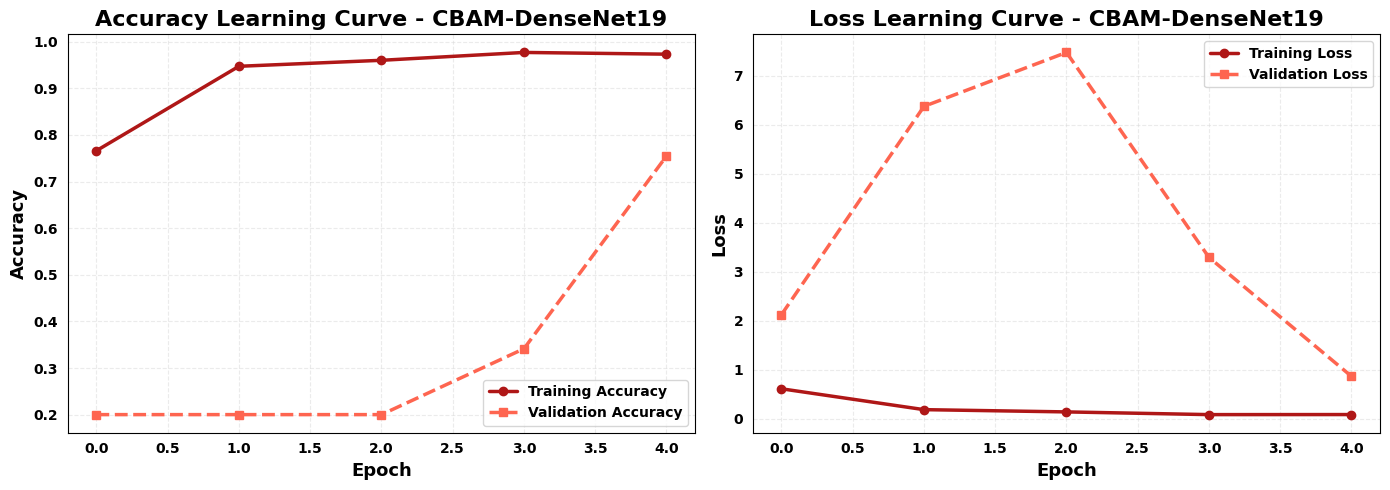

In [ ]:
# Create a figure with two side-by-side subplots for accuracy and loss learning curves.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot the training accuracy recorded at each epoch using a solid line and circular markers.
axes[0].plot(cbam_densenet19_history.history["accuracy"], label="Training Accuracy", color=COLORS[0], linewidth=2.5, marker="o")

# Plot the validation accuracy recorded at each epoch using a dashed line and square markers.
axes[0].plot(cbam_densenet19_history.history["val_accuracy"], label="Validation Accuracy", color=COLORS[2], linewidth=2.5, linestyle="--", marker="s")

# Set the title to identify the CBAM-DenseNet19 accuracy learning curve.
axes[0].set_title("Accuracy Learning Curve - CBAM-DenseNet19", fontsize=16, fontweight="bold", color=TEXT_COLOR)

# Label the horizontal axis to represent the training epochs.
axes[0].set_xlabel("Epoch", fontsize=13, fontweight="bold")

# Label the vertical axis to represent the model's accuracy values.
axes[0].set_ylabel("Accuracy", fontsize=13, fontweight="bold")

# Customize the axis tick labels for consistent font size and readability.
axes[0].tick_params(axis="both", labelsize=10, colors=TEXT_COLOR)

# Display a bold legend to distinguish training accuracy from validation accuracy.
axes[0].legend(prop={"weight": "bold", "size": 10})

# Add a dashed grid to make accuracy values easier to compare across epochs.
axes[0].grid(True, color=GRID_COLOR, linestyle="--", alpha=0.5)

# Plot the training loss recorded at each epoch using a solid line and circular markers.
axes[1].plot(cbam_densenet19_history.history["loss"], label="Training Loss", color=COLORS[0], linewidth=2.5, marker="o")

# Plot the validation loss recorded at each epoch using a dashed line and square markers.
axes[1].plot(cbam_densenet19_history.history["val_loss"], label="Validation Loss", color=COLORS[2], linewidth=2.5, linestyle="--", marker="s")

# Set the title to identify the CBAM-DenseNet19 loss learning curve.
axes[1].set_title("Loss Learning Curve - CBAM-DenseNet19", fontsize=16, fontweight="bold", color=TEXT_COLOR)

# Label the horizontal axis to represent the training epochs.
axes[1].set_xlabel("Epoch", fontsize=13, fontweight="bold")

# Label the vertical axis to represent the training and validation loss values.
axes[1].set_ylabel("Loss", fontsize=13, fontweight="bold")

# Customize the axis tick labels for consistent font size and readability.
axes[1].tick_params(axis="both", labelsize=10, colors=TEXT_COLOR)

# Display a bold legend to distinguish training loss from validation loss.
axes[1].legend(prop={"weight": "bold", "size": 10})

# Add a dashed grid to make loss values easier to compare across epochs.
axes[1].grid(True, color=GRID_COLOR, linestyle="--", alpha=0.5)

# Automatically adjust subplot spacing to prevent titles, labels, and legends from overlapping.
plt.tight_layout()

# Save both learning curves as a high-resolution PNG image in the CBAM-DenseNet19 output directory.
plt.savefig(CBAM_OUTPUT_DIR / "learning_curves.png", dpi=300, bbox_inches="tight")

# Display the completed accuracy and loss learning curves.
plt.show()

In [ ]:
# Load the best saved CBAM-DenseNet19 checkpoint (custom_objects helps Keras recognize the custom layer).
cbam_densenet19_model = tf.keras.models.load_model(CBAM_OUTPUT_DIR / "cbam_densenet19_best.keras", custom_objects={"SpatialAttentionPooling": SpatialAttentionPooling},safe_mode=False)

# Generate class probabilities for the test dataset.
test_probabilities = cbam_densenet19_model.predict(test_ds, verbose=1)

# Extract the true class labels from the test dataset.
y_test = test_df["label_idx"].to_numpy(dtype=np.int32)

# Convert predicted probabilities into class predictions.
test_predictions = np.argmax(test_probabilities, axis=1)

24/24 ━━━━━━━━━━━━━━━━━━━━ 6s 130ms/step


In [ ]:
# Calculate the required multiclass evaluation metrics.
cbam_accuracy = accuracy_score(y_test, test_predictions)
cbam_precision = precision_score(y_test, test_predictions, average="macro", zero_division=0)
cbam_recall = recall_score(y_test, test_predictions, average="macro", zero_division=0)
cbam_f1 = f1_score(y_test, test_predictions, average="macro", zero_division=0)
cbam_log_loss = log_loss(y_test, test_probabilities, labels=np.arange(NUM_CLASSES))

# Display the CBAM-DenseNet19 test evaluation metrics.
print("Test Evaluation Metrics - CBAM-DenseNet19")
print("-" * 40)
print(f"Accuracy  : {cbam_accuracy:.4f}")
print(f"Precision : {cbam_precision:.4f}")
print(f"Recall    : {cbam_recall:.4f}")
print(f"F1-score  : {cbam_f1:.4f}")
print(f"Log Loss  : {cbam_log_loss:.4f}")

Test Evaluation Metrics - CBAM-DenseNet19
----------------------------------------
Accuracy  : 0.7467
Precision : 0.7145
Recall    : 0.7467
F1-score  : 0.6830
Log Loss  : 0.9028


The CBAM-DenseNet19 model achieves an accuracy of 0.7467, precision of 0.7145, recall of 0.7467, and F1-score of 0.6830. These results indicate moderate classification performance, with precision and F1-score suggesting scope for improvement in prediction reliability and balance. The log loss of 0.9028 further highlights the need to improve predictive confidence. Overall, the model demonstrates potential, but further optimisation and validation are necessary to enhance classification accuracy and generalisation across unseen blood cell images.

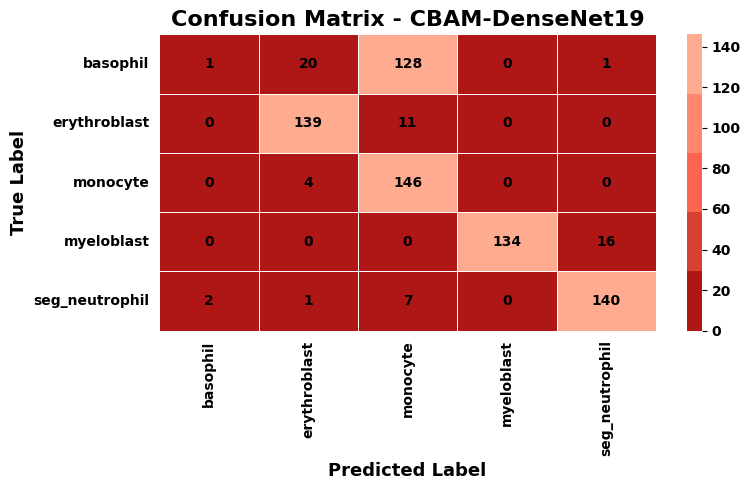

In [ ]:
# Create a figure and axis to display the CBAM-DenseNet19 confusion matrix.
fig, ax = plt.subplots(figsize=(8, 5))

# Calculate the confusion matrix and visualize the classification results using a heatmap.
sns.heatmap(confusion_matrix(y_test, test_predictions, labels=np.arange(NUM_CLASSES)), annot=True, fmt="d", cmap=sns.color_palette(COLORS, as_cmap=True), xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, linewidths=0.5, linecolor="white", annot_kws={"size": 10, "weight": "bold", "color": TEXT_COLOR}, ax=ax)

# Set the plot title to identify the CBAM-DenseNet19 confusion matrix.
ax.set_title("Confusion Matrix - CBAM-DenseNet19", fontweight="bold", fontsize=16, color=TEXT_COLOR)

# Label the horizontal axis to represent the classes predicted by the model.
ax.set_xlabel("Predicted Label", fontsize=13, fontweight="bold", color=TEXT_COLOR)

# Label the vertical axis to represent the actual classes in the test dataset.
ax.set_ylabel("True Label", fontsize=13, fontweight="bold", color=TEXT_COLOR)

# Customize the axis tick labels for consistent styling and readability.
ax.tick_params(axis="both", colors=TEXT_COLOR)

# Adjust the layout to prevent the title, axis labels, and class names from overlapping.
plt.tight_layout()

# Save the confusion matrix as a high-resolution PNG image in the CBAM output directory.
plt.savefig(CBAM_OUTPUT_DIR / "confusion_matrix.png", dpi=300, bbox_inches="tight")

# Display the completed confusion matrix for evaluating classification performance.
plt.show()

The CBAM-DenseNet19 confusion matrix shows strong classification for monocytes, with 146 correct predictions, and erythroblasts, with 139. However, basophils are frequently misclassified as monocytes, with 128 errors, highlighting a major weakness. Myeloblast classification records 134 correct predictions, whilst 16 are mistaken for segmented neutrophils. Overall, the model distinguishes several cell types effectively but struggles with basophils. Improving feature extraction and class-specific discrimination could reduce misclassification and strengthen the model’s overall reliability for blood cell classification.

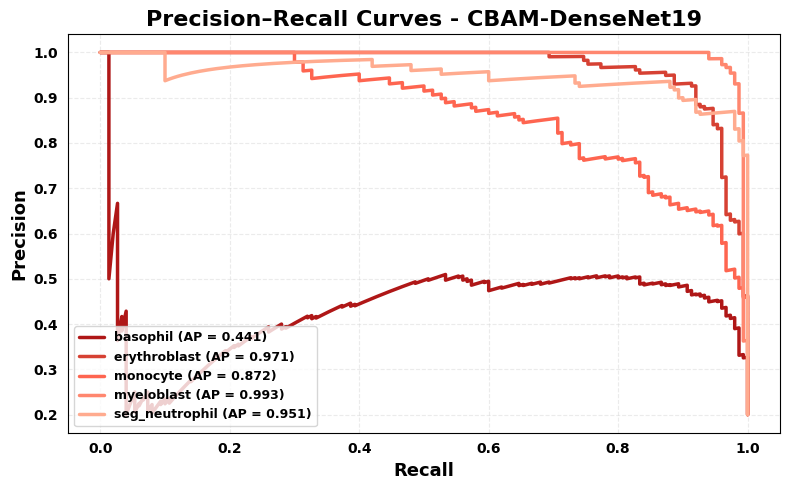

In [ ]:
# Convert the true test labels into a one-vs-rest binary format for class-wise evaluation.
y_test_binary = label_binarize(y_test, classes=np.arange(NUM_CLASSES))

# Create a figure and axis to display the precision–recall curves for all classes.
fig, ax = plt.subplots(figsize=(8, 5))

# Calculate and plot the precision–recall curve separately for each class.
for index, class_name in enumerate(CLASS_NAMES):

    # Calculate precision and recall values using the true binary labels and predicted class probabilities.
    precision_values, recall_values, _ = precision_recall_curve(y_test_binary[:, index], test_probabilities[:, index])

    # Calculate average precision (AP) to summarize the precision–recall performance for the current class.
    average_precision = average_precision_score(y_test_binary[:, index], test_probabilities[:, index])

    # Plot the precision–recall curve with a distinct colour and display the class name and AP score.
    ax.plot(recall_values, precision_values, color=COLORS[index % len(COLORS)], linewidth=2.5, label=f"{class_name} (AP = {average_precision:.3f})")

# Set the plot title to identify the CBAM-DenseNet19 precision–recall analysis.
ax.set_title("Precision–Recall Curves - CBAM-DenseNet19", fontweight="bold", fontsize=16, color=TEXT_COLOR)

# Label the horizontal axis to represent the recall values.
ax.set_xlabel("Recall", fontsize=13, fontweight="bold", color=TEXT_COLOR)

# Label the vertical axis to represent the precision values.
ax.set_ylabel("Precision", fontsize=13, fontweight="bold", color=TEXT_COLOR)

# Customize the axis tick labels to maintain consistent text colour and readability.
ax.tick_params(axis="both", colors=TEXT_COLOR)

# Display the class names and their average precision scores in the lower-left corner.
ax.legend(loc="lower left", prop={"weight": "bold", "size": 9}, frameon=True)

# Add a dashed grid to make precision and recall values easier to compare.
ax.grid(True, color=GRID_COLOR, linestyle="--", alpha=0.5)

# Adjust the layout to prevent the title, labels, and legend from overlapping.
plt.tight_layout()

# Save the precision–recall curves as a high-resolution PNG image in the CBAM output directory.
plt.savefig(CBAM_OUTPUT_DIR / "precision_recall_curves.png", dpi=300, bbox_inches="tight")

# Display the completed precision–recall curves for all classes.
plt.show()

The CBAM-DenseNet19 model shows varied precision-recall performance across cell classes. Myeloblasts achieve an average precision of 0.993, erythroblasts 0.971, segmented neutrophils 0.951, and monocytes 0.872. Basophils perform considerably worse, with an average precision of 0.441, reflecting difficulties distinguishing this class. Precision remains relatively high for most other categories across recall levels. Overall, the results highlight strong performance for several cell types but reveal substantial scope for improving basophil detection and overall classification consistency.

In [ ]:
# Generate the class-wise precision, recall, F1-score, and support report.
print("Classification Report- CBAM-DenseNet19")
print(classification_report(y_test, test_predictions, labels=np.arange(NUM_CLASSES), target_names=CLASS_NAMES, digits=4, zero_division=0))

Classification Report- CBAM-DenseNet19
                precision    recall  f1-score   support

      basophil     0.3333    0.0067    0.0131       150
  erythroblast     0.8476    0.9267    0.8854       150
      monocyte     0.5000    0.9733    0.6606       150
    myeloblast     1.0000    0.8933    0.9437       150
seg_neutrophil     0.8917    0.9333    0.9121       150

      accuracy                         0.7467       750
     macro avg     0.7145    0.7467    0.6830       750
  weighted avg     0.7145    0.7467    0.6830       750



## **Vision Transformer (ViT) Model**

The Vision Transformer (ViT) is a deep learning model designed for image classification. Unlike traditional Convolutional Neural Networks (CNNs), which primarily learn local image features using convolutional filters, ViT divides an image into fixed-size patches and uses a Transformer architecture to learn relationships between different regions of the image.

In [ ]:
# Define the directory where Vision Transformer outputs and saved files will be stored.
VIT_OUTPUT_DIR = Path("/kaggle/working/blood_cell_model_outputs/Vision_Transformer")

# Create the output directory and its parent directories if they do not already exist.
VIT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Set random seeds to improve the reproducibility of model initialization and training.
tf.keras.utils.set_random_seed(42)

# Define the input image dimensions required by the Vision Transformer.
VIT_IMAGE_SIZE = 224

# Set the height and width of each non-overlapping image patch to 16 pixels.
VIT_PATCH_SIZE = 16

# Calculate the total number of image patches generated from each input image.
VIT_NUM_PATCHES = (VIT_IMAGE_SIZE // VIT_PATCH_SIZE) ** 2

# Define the dimensionality of the embedding vector representing each image patch.
VIT_PROJECTION_DIM = 128

# Specify the number of attention heads used in each Transformer encoder block.
VIT_NUM_HEADS = 4

# Set the number of Transformer encoder blocks used to learn image features.
VIT_NUM_TRANSFORMER_BLOCKS = 4

# Define the number of neurons in the hidden layer of each Transformer MLP block.
VIT_MLP_DIM = 256

# Set the dropout rate used to reduce overfitting during training.
VIT_DROPOUT = 0.1

# Determine the number of output classes from the existing class-name list.
VIT_NUM_CLASSES = len(CLASS_NAMES)

In [ ]:
# Define a custom layer to divide input images into non-overlapping patches.
@tf.keras.utils.register_keras_serializable(package="BloodCellViT")
class Patches(tf.keras.layers.Layer):

    # Extract image patches and reshape them into a sequence for Transformer processing.
    def call(self, images):

        # Extract non-overlapping patches using the configured patch size and stride.
        patches = tf.image.extract_patches(
            images=images,  # Provide the input batch of images.
            sizes=[1, VIT_PATCH_SIZE, VIT_PATCH_SIZE, 1],  # Specify the patch extraction window.
            strides=[1, VIT_PATCH_SIZE, VIT_PATCH_SIZE, 1],  # Move the extraction window by one patch at a time.
            rates=[1, 1, 1, 1],  # Extract pixels without dilation.
            padding="VALID"  # Exclude incomplete patches at the image boundaries.
        )

        # Retrieve the flattened feature dimension of each extracted patch.
        patch_dim = patches.shape[-1]

        # Reshape the patches into (batch size, number of patches, patch dimension).
        return tf.reshape(patches, [tf.shape(images)[0], VIT_NUM_PATCHES, patch_dim])

In [ ]:
# Define a custom layer to project image patches into embeddings and encode their positions.
@tf.keras.utils.register_keras_serializable(package="BloodCellViT")
class PatchEncoder(tf.keras.layers.Layer):

    # Initialize the patch encoder with the number of patches and embedding dimension.
    def __init__(self, num_patches, projection_dim, **kwargs):

        # Initialize the parent Keras layer and preserve any additional layer settings.
        super().__init__(**kwargs)

        # Store the total number of patches processed for each image.
        self.num_patches = num_patches

        # Store the dimensionality of each patch embedding.
        self.projection_dim = projection_dim

        # Create a Dense layer to map flattened patches into the embedding space.
        self.projection = tf.keras.layers.Dense(projection_dim)

        # Create a trainable embedding layer to represent each patch's position.
        self.position_embedding = tf.keras.layers.Embedding(input_dim=num_patches, output_dim=projection_dim)

    # Convert extracted patches into embeddings and add positional information.
    def call(self, patches):

        # Generate a sequence of position indices for all image patches.
        positions = tf.range(start=0, limit=self.num_patches, delta=1)

        # Project the patches into the embedding space and add their positional embeddings.
        return self.projection(patches) + self.position_embedding(positions)

    # Return the layer configuration so the custom layer can be serialized and reconstructed.
    def get_config(self):

        # Retrieve the base Keras layer configuration.
        config = super().get_config()

        # Add the custom parameters required to recreate the patch encoder.
        config.update({"num_patches": self.num_patches, "projection_dim": self.projection_dim})

        # Return the complete configuration dictionary.
        return config

In [ ]:
# Define a function to construct the custom Vision Transformer classification model.
def build_vision_transformer():

    # Create the input layer for RGB images with dimensions of 224 × 224 × 3.
    inputs = tf.keras.layers.Input(shape=(VIT_IMAGE_SIZE, VIT_IMAGE_SIZE, 3))

    # Divide each input image into non-overlapping patches.
    patches = Patches()(inputs)

    # Convert the image patches into embeddings and add positional information.
    encoded_patches = PatchEncoder(VIT_NUM_PATCHES, VIT_PROJECTION_DIM)(patches)

    # Apply the configured number of Transformer encoder blocks to learn image representations.
    for _ in range(VIT_NUM_TRANSFORMER_BLOCKS):

        # Normalize the patch embeddings before applying multi-head self-attention.
        attention_input = tf.keras.layers.LayerNormalization(epsilon=1e-6)(encoded_patches)

        # Allow each patch to attend to other patches and learn relationships across the image.
        attention_output = tf.keras.layers.MultiHeadAttention(
            num_heads=VIT_NUM_HEADS,  # Specify the number of parallel attention heads.
            key_dim=VIT_PROJECTION_DIM // VIT_NUM_HEADS,  # Set the feature dimension handled by each attention head.
            dropout=VIT_DROPOUT  # Apply dropout within the attention mechanism.
        )(attention_input, attention_input)  # Use the same patch sequence for queries, keys, and values.

        # Apply dropout to the attention output to help reduce overfitting.
        attention_output = tf.keras.layers.Dropout(VIT_DROPOUT)(attention_output)

        # Add the original patch embeddings to the attention output through a residual connection.
        residual_output = tf.keras.layers.Add()([encoded_patches, attention_output])

        # Normalize the residual features before passing them through the MLP block.
        mlp_input = tf.keras.layers.LayerNormalization(epsilon=1e-6)(residual_output)

        # Expand the feature representation using a Dense layer with GELU activation.
        mlp_output = tf.keras.layers.Dense(VIT_MLP_DIM, activation="gelu")(mlp_input)

        # Apply dropout to the expanded features to improve generalization.
        mlp_output = tf.keras.layers.Dropout(VIT_DROPOUT)(mlp_output)

        # Project the MLP features back to the original embedding dimension.
        mlp_output = tf.keras.layers.Dense(VIT_PROJECTION_DIM)(mlp_output)

        # Apply dropout to the projected features before the next residual connection.
        mlp_output = tf.keras.layers.Dropout(VIT_DROPOUT)(mlp_output)

        # Add the MLP output to the residual features to preserve learned information.
        encoded_patches = tf.keras.layers.Add()([residual_output, mlp_output])

    # Normalize the final patch representations produced by the Transformer encoder blocks.
    features = tf.keras.layers.LayerNormalization(epsilon=1e-6)(encoded_patches)

    # Aggregate information from all patches into one feature vector per image.
    features = tf.keras.layers.GlobalAveragePooling1D()(features)

    # Apply dropout to the aggregated features to reduce overfitting.
    features = tf.keras.layers.Dropout(0.3)(features)

    # Learn higher-level classification features using a Dense layer with GELU activation.
    features = tf.keras.layers.Dense(128, activation="gelu")(features)

    # Apply additional dropout before the final classification layer.
    features = tf.keras.layers.Dropout(0.2)(features)

    # Predict the probability of each blood-cell class using the softmax activation.
    outputs = tf.keras.layers.Dense(VIT_NUM_CLASSES, activation="softmax")(features)

    # Create and return the complete Vision Transformer model.
    return tf.keras.Model(inputs=inputs, outputs=outputs, name="Vision_Transformer")

In [ ]:
# Build the Vision Transformer model using the defined architecture.
vit_model = build_vision_transformer()

# Configure the optimizer, loss function, and evaluation metric for model training.
vit_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),  loss="sparse_categorical_crossentropy",  metrics=["accuracy"]  )

# Display the model architecture, layer output shapes, and total trainable and non-trainable parameters.
vit_model.summary()

Model: "Vision_Transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patches (Patches)   │ (None, 196, 768)  │          0 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_encoder       │ (None, 196, 128)  │    123,520 │ patches[0][0]     │
│ (PatchEncoder)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 196, 128)  │        256 │ patch_encoder[0]… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 196, 128)  │     66,048 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 196, 128)  │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 196, 128)  │          0 │ patch_encoder[0]… │
│                     │                   │            │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 128)  │        256 │ add_3[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 196, 256)  │     33,024 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 196, 256)  │          0 │ dense_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 196, 128)  │     32,896 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 196, 128)  │          0 │ dense_10[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 196, 128)  │          0 │ add_3[0][0],      │
│                     │                   │            │ dropout_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 128)  │        256 │ add_4[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 196, 128)  │     66,048 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 196, 128)  │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_5 (Add)         │ (None, 196, 128)  │          0 │ add_4[0][0],      │
│                     │                   │            │ dropout_7[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 128)  │        256 │ add_5[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 196, 256)  │     33,024 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 670,853 (2.56 MB)

 Trainable params: 670,853 (2.56 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Configure callbacks to save the best model and prevent unnecessary training.
vit_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(filepath=str(VIT_OUTPUT_DIR / "vision_transformer_best.keras"),monitor="val_accuracy",mode="max",save_best_only=True,verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss",factor=0.5,patience=2,min_lr=1e-6,verbose=1)
]

In [ ]:
# Train the Vision Transformer using the existing training and validation datasets.
vit_history = vit_model.fit(train_ds,validation_data=validation_ds,epochs=5,callbacks=vit_callbacks,verbose=1)

Epoch 1/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step - accuracy: 0.2792 - loss: 1.6184
Epoch 1: val_accuracy improved from None to 0.60933, saving model to /kaggle/working/blood_cell_model_outputs/Vision_Transformer/vision_transformer_best.keras

Epoch 1: finished saving model to /kaggle/working/blood_cell_model_outputs/Vision_Transformer/vision_transformer_best.keras
110/110 ━━━━━━━━━━━━━━━━━━━━ 45s 191ms/step - accuracy: 0.3883 - loss: 1.3607 - val_accuracy: 0.6093 - val_loss: 0.8295 - learning_rate: 1.0000e-04
Epoch 2/5
109/110 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.6500 - loss: 0.8024
Epoch 2: val_accuracy improved from 0.60933 to 0.72267, saving model to /kaggle/working/blood_cell_model_outputs/Vision_Transformer/vision_transformer_best.keras

Epoch 2: finished saving model to /kaggle/working/blood_cell_model_outputs/Vision_Transformer/vision_transformer_best.keras
110/110 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - accuracy: 0.6851 - loss: 0.7297 - val_accuracy: 0.7227 - val_los

In [ ]:
# Save the final model and training history.
vit_model.save(VIT_OUTPUT_DIR / "vision_transformer_final.keras")
with open(VIT_OUTPUT_DIR / "training_history.csv", "w") as file:
    file.write("epoch,accuracy,val_accuracy,loss,val_loss\n")
    for epoch in range(len(vit_history.history["loss"])):
        file.write(f"{epoch + 1}," f"{vit_history.history['accuracy'][epoch]:.6f},"f"{vit_history.history['val_accuracy'][epoch]:.6f}," f"{vit_history.history['loss'][epoch]:.6f}," f"{vit_history.history['val_loss'][epoch]:.6f}\n")

# Display the best validation accuracy achieved during training.
best_epoch = int(tf.argmax(vit_history.history["val_accuracy"]).numpy()) + 1
best_val_accuracy = max(vit_history.history["val_accuracy"])
print(f"Best epoch: {best_epoch}")
print(f"Best validation accuracy: {best_val_accuracy:.4f}")
print(f"Model outputs saved to: {VIT_OUTPUT_DIR}")

Best epoch: 4
Best validation accuracy: 0.8840
Model outputs saved to: /kaggle/working/blood_cell_model_outputs/Vision_Transformer


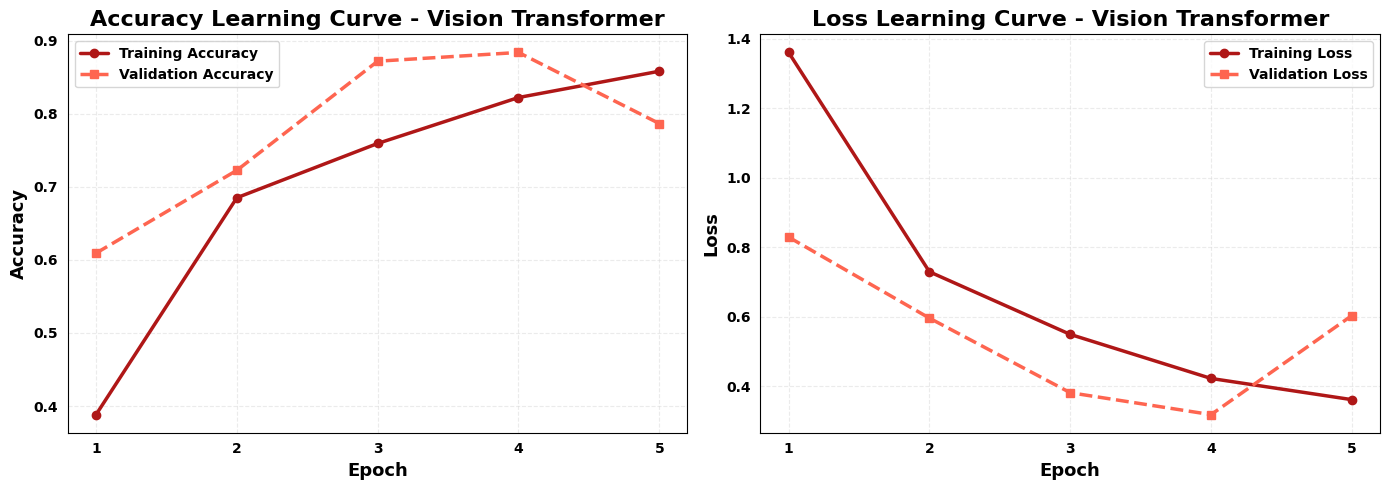

In [ ]:
# Create a figure containing two side-by-side subplots for accuracy and loss.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot training accuracy across all epochs using a solid line and circular markers.
axes[0].plot(vit_history.history["accuracy"], label="Training Accuracy", color=COLORS[0], linewidth=2.5, marker="o")

# Plot validation accuracy across all epochs using a dashed line and square markers.
axes[0].plot(vit_history.history["val_accuracy"], label="Validation Accuracy", color=COLORS[2], linewidth=2.5, linestyle="--", marker="s")

# Set the title to identify the Vision Transformer accuracy learning curve.
axes[0].set_title("Accuracy Learning Curve - Vision Transformer", fontsize=16, fontweight="bold", color=TEXT_COLOR)

# Label the horizontal axis to represent the training epochs.
axes[0].set_xlabel("Epoch", fontsize=13, fontweight="bold")

# Label the vertical axis to represent the model's accuracy values.
axes[0].set_ylabel("Accuracy", fontsize=13, fontweight="bold")

# Display epoch numbers starting from 1 instead of the default zero-based indexing.
axes[0].set_xticks(range(len(vit_history.history["accuracy"])), range(1, len(vit_history.history["accuracy"]) + 1))

# Customize tick label size and color for better readability.
axes[0].tick_params(axis="both", labelsize=10, colors=TEXT_COLOR)

# Display a bold legend to distinguish training accuracy from validation accuracy.
axes[0].legend(prop={"weight": "bold", "size": 10})

# Add a dashed grid to make accuracy values easier to compare across epochs.
axes[0].grid(True, color=GRID_COLOR, linestyle="--", alpha=0.5)

# Plot training loss across all epochs using a solid line and circular markers.
axes[1].plot(vit_history.history["loss"], label="Training Loss", color=COLORS[0], linewidth=2.5, marker="o")

# Plot validation loss across all epochs using a dashed line and square markers.
axes[1].plot(vit_history.history["val_loss"], label="Validation Loss", color=COLORS[2], linewidth=2.5, linestyle="--", marker="s")

# Set the title to identify the Vision Transformer loss learning curve.
# Set the title to identify the CBAM-DenseNet19 loss learning curve.
axes[1].set_title("Loss Learning Curve - Vision Transformer", fontsize=16, fontweight="bold", color=TEXT_COLOR)

# Label the horizontal axis to represent the training epochs.
axes[1].set_xlabel("Epoch", fontsize=13, fontweight="bold")

# Label the vertical axis to represent the training and validation loss values.
axes[1].set_ylabel("Loss", fontsize=13, fontweight="bold")

# Display epoch numbers starting from 1 instead of the default zero-based indexing.
axes[1].set_xticks(range(len(vit_history.history["loss"])), range(1, len(vit_history.history["loss"]) + 1))

# Customize tick label size and color for better readability.
axes[1].tick_params(axis="both", labelsize=10, colors=TEXT_COLOR)

# Display a bold legend to distinguish training loss from validation loss.
axes[1].legend(prop={"weight": "bold", "size": 10})

# Add a dashed grid to make loss values easier to compare across epochs.
axes[1].grid(True, color=GRID_COLOR, linestyle="--", alpha=0.5)

# Automatically adjust subplot spacing to prevent titles and labels from overlapping.
plt.tight_layout()

# Save both learning curves as a high-resolution PNG image in the Vision Transformer output directory.
plt.savefig(VIT_OUTPUT_DIR / "learning_curves.png", dpi=300, bbox_inches="tight")

# Display the completed accuracy and loss learning curves.
plt.show()

The Vision Transformer demonstrates improving training accuracy, reaching 0.86 by epoch 5, whilst validation accuracy peaks at 0.885 during epoch 4 before declining. Training loss decreases steadily, indicating effective learning. However, validation loss rises from 0.32 at epoch 4 to 0.60 at epoch 5, suggesting potential overfitting in later training. Overall, the model shows promising performance, with epoch 4 appearing to offer the best validation results. Early stopping could help preserve generalisation and improve reliability on unseen data.

In [ ]:
# Load the best Vision Transformer checkpoint.
vit_model = tf.keras.models.load_model(VIT_OUTPUT_DIR / "vision_transformer_best.keras")

# Evaluate the best model on the independent test dataset.
vit_test_loss, vit_test_accuracy = vit_model.evaluate(test_ds, verbose=1)

# Generate class probabilities and predicted labels for the test images.
vit_test_probabilities = vit_model.predict(test_ds, verbose=1)
vit_test_predictions = np.argmax(vit_test_probabilities, axis=1)
vit_y_test = np.concatenate([labels.numpy() for _, labels in test_ds], axis=0).astype(int)

24/24 ━━━━━━━━━━━━━━━━━━━━ 4s 69ms/step - accuracy: 0.8747 - loss: 0.3161
24/24 ━━━━━━━━━━━━━━━━━━━━ 4s 88ms/step


In [ ]:
# Calculate the multiclass test evaluation metrics.
vit_precision = precision_score(vit_y_test, vit_test_predictions, average="macro", zero_division=0)
vit_recall = recall_score(vit_y_test, vit_test_predictions, average="macro", zero_division=0)
vit_f1 = f1_score(vit_y_test, vit_test_predictions, average="macro", zero_division=0)
vit_log_loss = log_loss(vit_y_test, vit_test_probabilities, labels=np.arange(VIT_NUM_CLASSES))

# Display the Vision Transformer test results.
print("Test Evaluation Metrics - Vision Transformer")
print("-" * 45)
print(f"Test Accuracy  : {vit_test_accuracy:.4f}")
print(f"Test Precision : {vit_precision:.4f}")
print(f"Test Recall    : {vit_recall:.4f}")
print(f"Test F1-score  : {vit_f1:.4f}")
print(f"Test Log Loss  : {vit_log_loss:.4f}")

Test Evaluation Metrics - Vision Transformer
---------------------------------------------
Test Accuracy  : 0.8747
Test Precision : 0.8760
Test Recall    : 0.8747
Test F1-score  : 0.8749
Test Log Loss  : 0.3161


The Vision Transformer achieves strong test performance, with accuracy of 0.8747, precision of 0.8760, recall of 0.8747, and an F1-score of 0.8749. These results indicate consistent classification performance and a good balance between precision and recall. The log loss of 0.3161 suggests reasonably reliable predictive confidence. Overall, the model demonstrates promising classification capability and generalisation, although further evaluation on independent datasets could help establish its robustness and suitability for automated blood cell image classification.

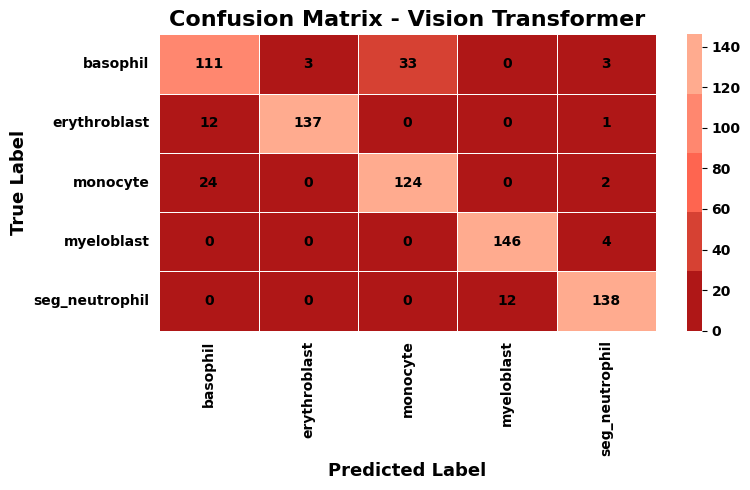

In [ ]:
# Generate the confusion matrix by comparing the true test labels with the predicted test labels.
vit_cm = confusion_matrix(vit_y_test, vit_test_predictions, labels=np.arange(VIT_NUM_CLASSES))

# Create a figure and axis to display the confusion matrix as a heatmap.
fig, ax = plt.subplots(figsize=(8, 5))

# Display the confusion matrix with annotated prediction counts, class labels, and a custom colour palette.
sns.heatmap(vit_cm, annot=True, fmt="d", cmap=sns.color_palette(COLORS, as_cmap=True), xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, linewidths=0.5, linecolor="white", annot_kws={"size": 10, "weight": "bold", "color": TEXT_COLOR}, ax=ax)

# Set the title to identify the Vision Transformer confusion matrix.
ax.set_title("Confusion Matrix - Vision Transformer", fontsize=16, fontweight="bold", color=TEXT_COLOR)

# Label the horizontal axis to represent the classes predicted by the model.
ax.set_xlabel("Predicted Label", fontsize=13, fontweight="bold")

# Label the vertical axis to represent the actual classes in the test dataset.
ax.set_ylabel("True Label", fontsize=13, fontweight="bold")

# Customize the axis tick labels for consistent font size and readability.
ax.tick_params(axis="both", labelsize=10, colors=TEXT_COLOR)

# Rotate the predicted class labels vertically to improve readability.
plt.xticks(rotation=90)

# Keep the true class labels horizontal for easier identification.
plt.yticks(rotation=0)

# Adjust the layout to prevent the title, labels, and class names from overlapping.
plt.tight_layout()

# Save the confusion matrix as a high-resolution PNG image in the Vision Transformer output directory.
plt.savefig(VIT_OUTPUT_DIR / "confusion_matrix.png", dpi=300, bbox_inches="tight")

# Display the completed confusion matrix for evaluating classification performance.
plt.show()

The Vision Transformer confusion matrix shows strong classification for myeloblasts, with 146 correct predictions, and erythroblasts, with 137. Basophils achieve 111 correct predictions, whilst 33 are misclassified as monocytes. Monocytes record 124 correct predictions, with 24 incorrectly classified as basophils. Segmented neutrophils achieve 138 correct predictions, although 12 are mistaken for myeloblasts. Overall, the model performs well across most cell classes, but distinguishing basophils from monocytes remains a key area for improvement.

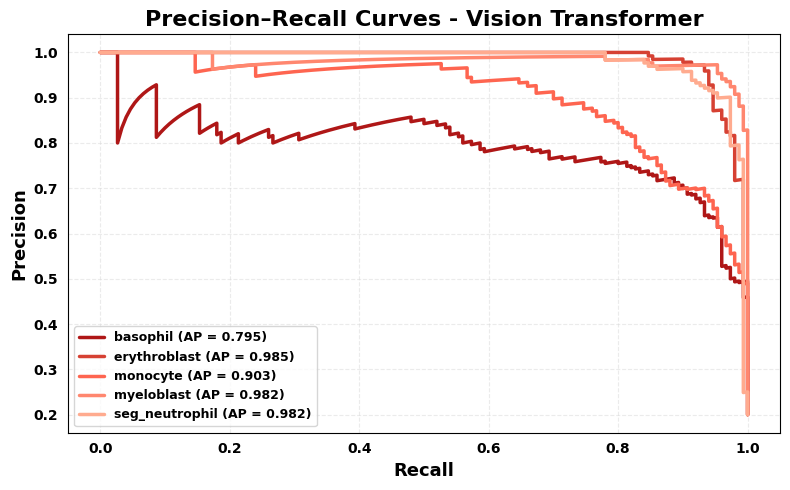

In [ ]:
# Convert the test labels into a one-vs-rest binary format for class-wise evaluation.
vit_y_test_binary = label_binarize(vit_y_test, classes=np.arange(VIT_NUM_CLASSES))

# Create a figure and axis for displaying the precision–recall curves.
fig, ax = plt.subplots(figsize=(8, 5))

# Calculate and plot the precision–recall curve separately for each class.
for i, class_name in enumerate(CLASS_NAMES):

    # Calculate precision and recall values using the true binary labels and predicted probabilities.
    precision_values, recall_values, _ = precision_recall_curve(vit_y_test_binary[:, i], vit_test_probabilities[:, i])

    # Calculate average precision (AP) to summarize the precision–recall performance for the current class.
    average_precision = average_precision_score(vit_y_test_binary[:, i], vit_test_probabilities[:, i])

    # Plot the precision–recall curve and include the class name and AP score in the legend.
    ax.plot(recall_values, precision_values, color=COLORS[i % len(COLORS)], linewidth=2.5, label=f"{class_name} (AP = {average_precision:.3f})")

# Set the plot title to identify the Vision Transformer precision–recall analysis.
ax.set_title("Precision–Recall Curves - Vision Transformer", fontsize=16, fontweight="bold", color=TEXT_COLOR)

# Label the horizontal axis to represent the recall values.
ax.set_xlabel("Recall", fontsize=13, fontweight="bold")

# Label the vertical axis to represent the precision values.
ax.set_ylabel("Precision", fontsize=13, fontweight="bold")

# Customize the axis tick labels for clear and consistent presentation.
ax.tick_params(axis="both", labelsize=10, colors=TEXT_COLOR)

# Display the class names and their corresponding average precision scores in the legend.
ax.legend(prop={"weight": "bold", "size": 9})

# Add a dashed grid to make precision and recall values easier to compare.
ax.grid(True, color=GRID_COLOR, linestyle="--", alpha=0.5)

# Adjust the layout to prevent the title, axis labels, and legend from overlapping.
plt.tight_layout()

# Save the precision–recall curves as a high-resolution PNG image.
plt.savefig(VIT_OUTPUT_DIR / "precision_recall_curves.png", dpi=300, bbox_inches="tight")

# Display the completed precision–recall curves for all classes.
plt.show()

The Vision Transformer demonstrates strong precision-recall performance across most cell classes. Erythroblasts achieve an average precision of 0.985, whilst myeloblasts and segmented neutrophils both reach 0.982. Monocytes achieve 0.903, indicating good classification performance. Basophils record a lower average precision of 0.795, suggesting greater difficulty distinguishing this class. Overall, the model maintains high precision across most recall levels, although basophil detection remains an area for improvement to achieve more consistent classification across all blood cell categories.

In [ ]:
# Generate the class-wise precision, recall, F1-score, and support report.
print("Vision Transformer: Classification Report")
print(classification_report(vit_y_test, vit_test_predictions, labels=np.arange(VIT_NUM_CLASSES), target_names=CLASS_NAMES, digits=4, zero_division=0))

Vision Transformer: Classification Report
                precision    recall  f1-score   support

      basophil     0.7551    0.7400    0.7475       150
  erythroblast     0.9786    0.9133    0.9448       150
      monocyte     0.7898    0.8267    0.8078       150
    myeloblast     0.9241    0.9733    0.9481       150
seg_neutrophil     0.9324    0.9200    0.9262       150

      accuracy                         0.8747       750
     macro avg     0.8760    0.8747    0.8749       750
  weighted avg     0.8760    0.8747    0.8749       750



## **Model Comparison**

In [ ]:
# Create the results comparison DataFrame using the calculated test metrics.
model_comparison_df = pd.DataFrame([
    {"Model": "CNN-ML","Accuracy": cnn_ml_accuracy,"Precision": cnn_ml_precision,"Recall": cnn_ml_recall,"F1-score": cnn_ml_f1,"Log Loss": cnn_ml_log_loss},
    {"Model": "CBAM-DenseNet19","Accuracy": cbam_accuracy,"Precision": cbam_precision,"Recall": cbam_recall,"F1-score": cbam_f1,"Log Loss": cbam_log_loss},
    {"Model": "Vision Transformer","Accuracy": vit_test_accuracy,"Precision": vit_precision,"Recall": vit_recall,"F1-score": vit_f1,"Log Loss": vit_log_loss}
])

# Display the model comparison results rounded to four decimal places.
display(model_comparison_df.round(4))

# Save the model comparison results to a CSV file.
model_comparison_df.to_csv(CBAM_OUTPUT_DIR.parent / "model_results_comparison.csv", index=False)

,Model,Accuracy,Precision,Recall,F1-score,Log Loss
0,CNN-ML,0.9693,0.9695,0.9693,0.9693,0.1420
1,CBAM-DenseNet19,0.7467,0.7145,0.7467,0.6830,0.9028
2,Vision Transformer,0.8747,0.8760,0.8747,0.8749,0.3161


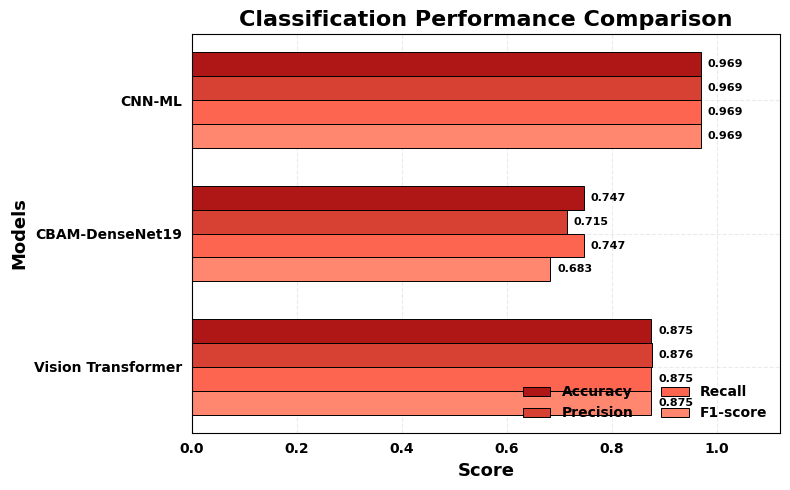

In [ ]:
# Define the colours for each evaluation metric.
metric_colors = {"Accuracy": COLORS[0], "Precision": COLORS[1], "Recall": COLORS[2], "F1-score": COLORS[3]}

# Create the figure and axes for the classification performance comparison.
fig, ax = plt.subplots(figsize=(8, 5))

# Define the positions and bar height for each model.
y = np.arange(len(model_comparison_df))
bar_height = 0.18

# Plot horizontal bars for each evaluation metric with annotations.
for i, (metric, color) in enumerate(metric_colors.items()):
    values = model_comparison_df[metric]
    positions = y + (i - 1.5) * bar_height
    bars = ax.barh(positions, values, height=bar_height, color=color, label=metric, edgecolor="black", linewidth=0.7)

    # Display the metric scores at the end of each bar.
    for bar, value in zip(bars, values):
        ax.annotate(f"{value:.3f}", (bar.get_width(), bar.get_y() + bar.get_height() / 2), xytext=(5, 0), textcoords="offset points", ha="left", va="center", fontsize=8, fontweight="bold", color=TEXT_COLOR)

# Add model names, axis labels, and the plot title.
ax.set_yticks(y)
ax.set_yticklabels(model_comparison_df["Model"])
ax.set_xlabel("Score")
ax.set_ylabel("Models")
ax.set_title("Classification Performance Comparison", fontsize=16, fontweight="bold")
ax.set_xlim(0, 1.12)
ax.invert_yaxis()

# Display the legend and format the plot.
ax.legend(loc="lower right", frameon=False, ncol=2)
ax.grid(axis="x", color=GRID_COLOR, linestyle="--", alpha=0.5)
ax.set_axisbelow(True)
plt.tight_layout()

plt.show()

The classification comparison highlights CNN-ML as the strongest model, achieving consistent accuracy, precision, recall, and F1-score of approximately 0.969. The Vision Transformer follows with scores around 0.875, demonstrating good classification performance. CBAM-DenseNet19 performs comparatively poorly, with accuracy and recall of 0.747, precision of 0.715, and an F1-score of 0.683. Overall, CNN-ML offers the most reliable classification results, whilst CBAM-DenseNet19 requires further optimisation to improve predictive performance and consistency across blood cell categories.

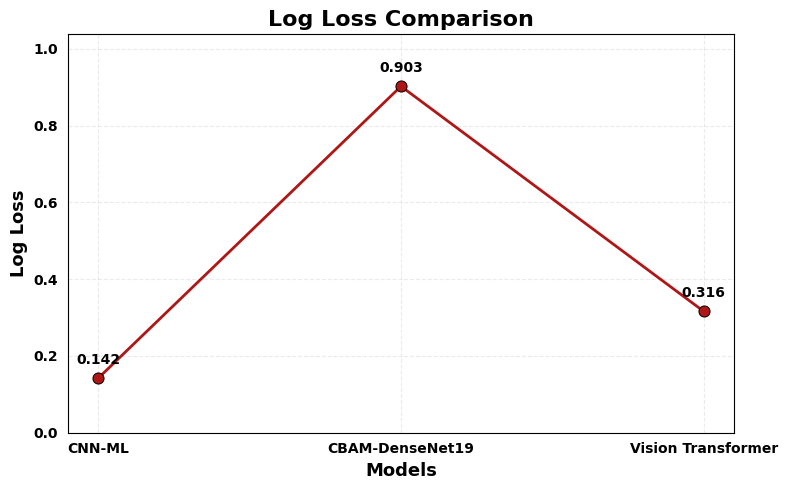

In [ ]:
# Create the figure and axes for the log loss comparison.
fig, ax = plt.subplots(figsize=(8, 5))

# Plot log loss values for all three models using a line and point markers.
x = np.arange(len(model_comparison_df))
values = model_comparison_df["Log Loss"]
ax.plot(x, values, color=COLORS[0], marker="o", markersize=8, linewidth=2, markeredgecolor="black", markeredgewidth=0.7)

# Add annotations to display the log loss value for each model.
for point_x, value in zip(x, values):
    ax.annotate(f"{value:.3f}", (point_x, value), xytext=(0, 8), textcoords="offset points", ha="center", va="bottom", fontsize=10, fontweight="bold", color=TEXT_COLOR)

# Add model names, axis labels, and the plot title.
ax.set_xticks(x)
ax.set_xticklabels(model_comparison_df["Model"], rotation=0)
ax.set_xlabel("Models")
ax.set_ylabel("Log Loss")
ax.set_title("Log Loss Comparison", fontsize=16, fontweight="bold")

# Add space above the highest value to keep annotations visible.
ax.set_ylim(bottom=0, top=max(values) * 1.15 if max(values) > 0 else 1)

# Display the grid and format the plot.
ax.grid(axis="y", color=GRID_COLOR, linestyle="--", alpha=0.5)
ax.set_axisbelow(True)
plt.tight_layout()

# Save and display the log loss comparison plot.
plt.savefig(CBAM_OUTPUT_DIR.parent / "log_loss_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

The log loss comparison shows that CNN-ML performs best, achieving the lowest log loss of 0.142. The Vision Transformer follows with 0.316, indicating reasonably reliable predictive confidence. CBAM-DenseNet19 records the highest log loss of 0.903, suggesting less reliable probability estimates. Overall, CNN-ML demonstrates the strongest predictive performance, combining lower log loss with superior classification metrics. The results indicate that CNN-ML provides the most reliable predictions among the three models evaluated in this study.

## **Save the Model**

In [ ]:
# Identify the best-performing model based on test accuracy.
best_model_name = model_comparison_df.loc[model_comparison_df["Accuracy"].idxmax(), "Model"]
best_accuracy = model_comparison_df.loc[model_comparison_df["Accuracy"].idxmax(), "Accuracy"]

# Define the trained models and their output file paths.
model_objects = {"CNN-ML": cnn_ml_model, "CBAM-DenseNet19": cbam_densenet19_model, "Vision Transformer": vit_model}
model_paths = {"CNN-ML": OUTPUT_DIR / "cnn_ml_best.keras", "CBAM-DenseNet19": CBAM_OUTPUT_DIR / "cbam_densenet19_best.keras", "Vision Transformer": VIT_OUTPUT_DIR / "vision_transformer_best.keras"}

# Save the best-performing model.
best_model = model_objects[best_model_name]
best_model_path = model_paths[best_model_name]
best_model.save(best_model_path)

# Display the best model and its saved location.
print(f"Best Model: {best_model_name}")
print(f"Test Accuracy: {best_accuracy:.4f}")
print(f"Saved Model Path: {best_model_path}")

Best Model: CNN-ML
Test Accuracy: 0.9693
Saved Model Path: /kaggle/working/blood_cell_model_outputs/CNN_ML/cnn_ml_best.keras


## Conclusion

The project successfully evaluated three deep learning models for image-based classification. CNN-ML achieved the best overall performance, with accuracy, precision, recall and F1-score of approximately 0.969 and the lowest log loss of 0.142, demonstrating strong and consistent classification performance. The Vision Transformer also performed well, achieving approximately 0.875 across the classification metrics, with a log loss of 0.316. In contrast, CBAM-DenseNet19 showed comparatively lower performance, with an F1-score of 0.683 and the highest log loss of 0.903. Overall, CNN-ML proved to be the most effective model, offering the best balance of classification performance and predictive probability quality.